## 1. Import Dependencies

In [11]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from ydata_profiling import ProfileReport

%matplotlib inline


### load the dataset 

load data set and check the description

In [12]:
dataset = pd.read_csv('../data/All_three_combined.csv')

dataset.describe()

,Country Name,Country Code,Series Name,Series Code,2000 [YR2000],2001 [YR2001],2002 [YR2002],2003 [YR2003],2004 [YR2004],2005 [YR2005],...,2015 [YR2015],2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024]
count,798,798,798,798,798,798,798,798,798,798,...,798,798,798,798,798,798,798,798,798,798
unique,266,266,3,3,655,661,659,660,660,680,...,668,676,673,671,686,668,670,670,643,634
top,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,..,..,..,..,..,..,...,..,..,..,..,..,..,..,..,..,..
freq,3,3,266,266,138,130,134,133,132,110,...,121,117,120,122,105,124,122,122,150,160


#### Generate a data overview report for the combined dataset

In [13]:
# report = ProfileReport(dataset, title="Pandas Profiling Report", explorative=True)
# report.to_file("../reports/gdp_per_capita_report.html")

## 2. Question 1: How are GDP per capita, unemployment, and life expectancy related across countries from 2000 to 2024?

Approach: reshape to one row per country-year, then (1) look at each pairwise relationship and (2) check whether it holds in every year.

In [14]:
# Reshape from World Bank format (one row per country x indicator, one column per year)
# to a tidy table with one row per country-year and one column per indicator.
year_cols = [c for c in dataset.columns if '[YR' in c]
long = dataset.dropna(subset=['Series Code']).melt(
    id_vars=['Country Name', 'Country Code', 'Series Code'],
    value_vars=year_cols, var_name='year', value_name='value')

long['year'] = long['year'].str[:4].astype(int)                             # "2000 [YR2000]" -> 2000
long['value'] = pd.to_numeric(long['value'].replace('..', np.nan), errors='coerce')  # ".." means missing
long['indicator'] = long['Series Code'].map({
    'NY.GDP.PCAP.CD': 'gdp_per_capita',
    'SP.DYN.LE00.IN': 'life_expectancy',
    'SL.UEM.TOTL.NE.ZS': 'unemployment_rate'})

df = (long.set_index(['Country Name', 'Country Code', 'year', 'indicator'])['value']
          .unstack('indicator').reset_index())

# The file also contains regional/income-group aggregates (World, Euro area, ...).
# They would double count countries, so drop them.
aggregate_codes = {
    'AFE', 'AFW', 'ARB', 'CEB', 'CSS', 'EAP', 'EAR', 'EAS', 'ECA', 'ECS', 'EMU', 'EUU',
    'FCS', 'HIC', 'HPC', 'IBD', 'IBT', 'IDA', 'IDB', 'IDX', 'INX', 'LAC', 'LCN', 'LDC',
    'LIC', 'LMC', 'LMY', 'LTE', 'MEA', 'MIC', 'MNA', 'NAC', 'OED', 'OSS', 'PRE', 'PSS',
    'PST', 'SAS', 'SSA', 'SSF', 'SST', 'TEA', 'TEC', 'TLA', 'TMN', 'TSA', 'TSS', 'UMC', 'WLD'}
df = df[~df['Country Code'].isin(aggregate_codes)].copy()

df['log_gdp'] = np.log10(df['gdp_per_capita'])   # GDP is highly skewed, so analyse it on a log scale


def add_trend(ax, x, y, log_x=False, color='red'):
    """Draw a least-squares line (fitted on log10(x) if log_x) and return its slope."""
    m = x.notna() & y.notna()
    xv = np.log10(x[m]) if log_x else x[m]
    slope, intercept = np.polyfit(xv, y[m], 1)
    xs = np.linspace(xv.min(), xv.max(), 100)
    ax.plot(10 ** xs if log_x else xs, slope * xs + intercept, color=color, lw=2)
    return slope


indicator_cols = ['gdp_per_capita', 'life_expectancy', 'unemployment_rate']
coverage = df[indicator_cols].notna().mean().mul(100).round(0)
print(f'{df["Country Name"].nunique()} countries, 2000-2024. Share of country-years with data: '
      + ', '.join(f'{k} {v:.0f}%' for k, v in coverage.items()))

218 countries, 2000-2024. Share of country-years with data: gdp_per_capita 97%, life_expectancy 100%, unemployment_rate 58%


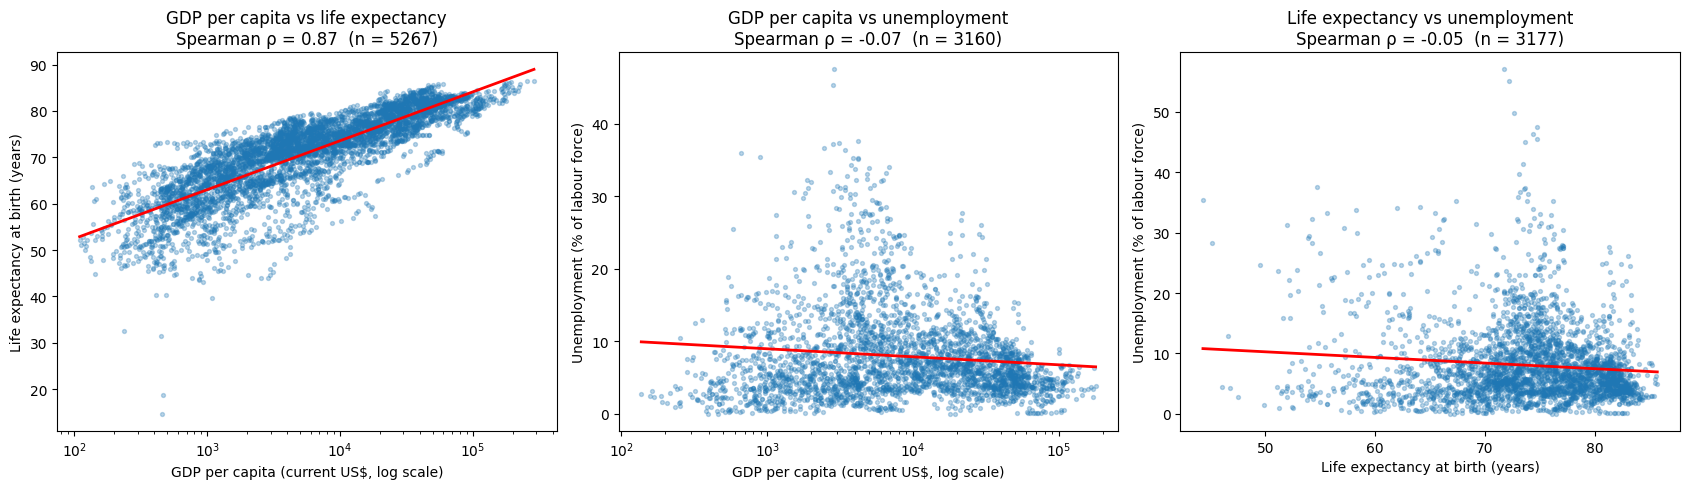

Each 10x increase in GDP per capita is associated with about 10.5 more years of life expectancy.


In [15]:
# Figure 1: the three pairwise relationships (each point is one country-year).
# Spearman (rank-based) is used because GDP is heavily skewed and the relationships are not linear.
labels = {'gdp_per_capita': 'GDP per capita (current US$, log scale)',
          'life_expectancy': 'Life expectancy at birth (years)',
          'unemployment_rate': 'Unemployment (% of labour force)'}
pairs = [('gdp_per_capita', 'life_expectancy', 'GDP per capita vs life expectancy'),
         ('gdp_per_capita', 'unemployment_rate', 'GDP per capita vs unemployment'),
         ('life_expectancy', 'unemployment_rate', 'Life expectancy vs unemployment')]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (x, y, title) in zip(axes, pairs):
    d = df[[x, y]].dropna()
    log_x = x == 'gdp_per_capita'
    ax.scatter(d[x], d[y], s=8, alpha=0.3)
    if log_x:
        ax.set_xscale('log')
    slope = add_trend(ax, d[x], d[y], log_x=log_x)
    if (x, y) == ('gdp_per_capita', 'life_expectancy'):
        le_slope = slope
    rho = d[x].corr(d[y], method='spearman')
    ax.set_title(f'{title}\nSpearman ρ = {rho:.2f}  (n = {len(d)})')
    ax.set_xlabel(labels[x])
    ax.set_ylabel(labels[y])
plt.tight_layout()
plt.show()

print(f'Each 10x increase in GDP per capita is associated with about {le_slope:.1f} more years of life expectancy.')

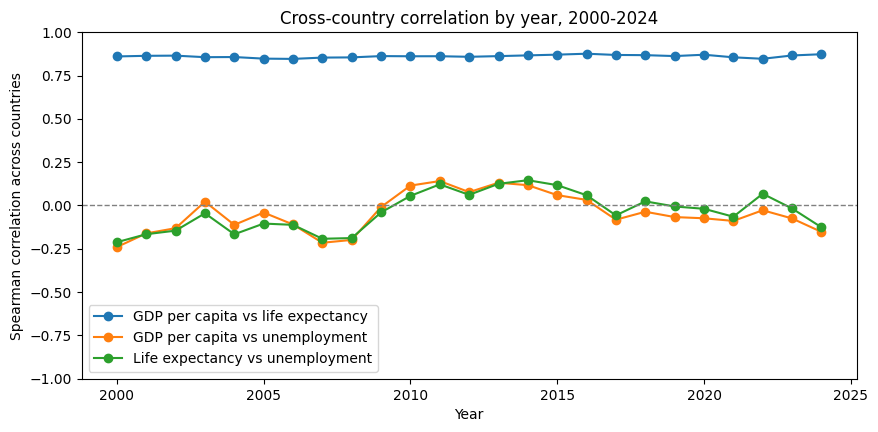

,GDP per capita vs life expectancy,GDP per capita vs unemployment,Life expectancy vs unemployment
min,0.85,-0.24,-0.21
max,0.88,0.14,0.15


In [16]:
# Figure 2: is the relationship stable over time? Spearman correlation recomputed for each year.
yearly = pd.DataFrame({
    title: df.groupby('year').apply(lambda g: g[x].corr(g[y], method='spearman'), include_groups=False)
    for x, y, title in pairs})

ax = yearly.plot(marker='o', figsize=(10, 4.5))
ax.axhline(0, color='grey', lw=1, ls='--')
ax.set_ylim(-1, 1)
ax.set_xlabel('Year')
ax.set_ylabel('Spearman correlation across countries')
ax.set_title('Cross-country correlation by year, 2000-2024')
plt.show()

yearly.agg(['min', 'max']).round(2)

### Answer (Question 1)

- **GDP per capita and life expectancy are strongly linked** (ρ ≈ 0.87). Each 10x increase in GDP per capita goes with about 10.5 more years of life, with diminishing returns at high incomes. The link is just as strong in every year from 2000 to 2024 (ρ between 0.85 and 0.88).
- **Unemployment is essentially unrelated to either indicator** (|ρ| < 0.1 overall). Year by year it drifts between about -0.24 and +0.15 with no consistent direction.
- **Decision:** treat GDP per capita (on a log scale) as a strong marker of population health. Do not use it to predict unemployment, which needs to be explained by labour-market factors instead (see Question 2).
- *Caveats:* correlation is not causation; GDP is in current US$ (not PPP); unemployment is only reported for about 58% of country-years.

## 3. Question 2: Do countries with higher GDP per capita tend to have lower unemployment rates?

Two views: **between countries** (each country's 2000-2024 average) and **within countries** (is a country's unemployment lower in its own richer years?). Uses `df` and `add_trend` from Question 1.

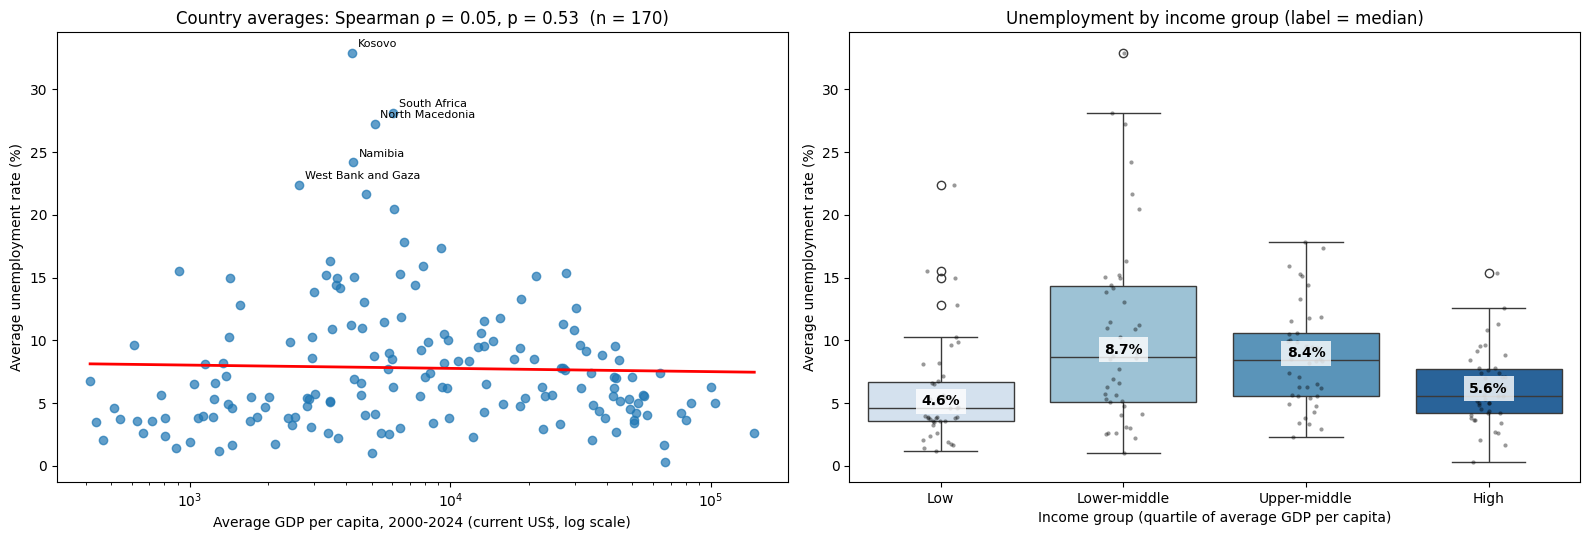

In [17]:
# Figure 3: between countries. One point per country (2000-2024 averages); countries with
# fewer than 5 years of unemployment data are dropped so averages are not based on one year.
n_unemp = df.groupby('Country Name')['unemployment_rate'].count().rename('n_unemp')
avg = (df.groupby('Country Name')
         .agg(gdp_per_capita=('gdp_per_capita', 'mean'),
              unemployment_rate=('unemployment_rate', 'mean'))
         .join(n_unemp))
avg = avg[avg['n_unemp'] >= 5].dropna(subset=['gdp_per_capita', 'unemployment_rate']).copy()
avg['log_gdp'] = np.log10(avg['gdp_per_capita'])
avg['income_group'] = pd.qcut(avg['gdp_per_capita'], 4,
                              labels=['Low', 'Lower-middle', 'Upper-middle', 'High'])

# Spearman correlation with a permutation p-value (shuffle unemployment 10,000 times).
rng = np.random.default_rng(42)
rank_x, rank_y = avg['log_gdp'].rank().to_numpy(), avg['unemployment_rate'].rank().to_numpy()
rho = np.corrcoef(rank_x, rank_y)[0, 1]
null = np.array([np.corrcoef(rank_x, rng.permutation(rank_y))[0, 1] for _ in range(10_000)])
p_value = (np.abs(null) >= abs(rho)).mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

ax = axes[0]
ax.scatter(avg['gdp_per_capita'], avg['unemployment_rate'], alpha=0.7)
ax.set_xscale('log')
add_trend(ax, avg['gdp_per_capita'], avg['unemployment_rate'], log_x=True)
for name in avg['unemployment_rate'].nlargest(5).index:
    r = avg.loc[name]
    ax.annotate(name, (r['gdp_per_capita'], r['unemployment_rate']), fontsize=8,
                xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('Average GDP per capita, 2000-2024 (current US$, log scale)')
ax.set_ylabel('Average unemployment rate (%)')
ax.set_title(f'Country averages: Spearman ρ = {rho:.2f}, p = {p_value:.2f}  (n = {len(avg)})')

ax = axes[1]
sns.boxplot(data=avg, x='income_group', y='unemployment_rate',
            hue='income_group', legend=False, palette='Blues', ax=ax)
sns.stripplot(data=avg, x='income_group', y='unemployment_rate', color='black', alpha=0.4, size=3, ax=ax)
medians = avg.groupby('income_group', observed=True)['unemployment_rate'].median()
for i, m in enumerate(medians):
    ax.text(i, m, f'{m:.1f}%', ha='center', va='bottom', fontweight='bold',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
ax.set_xlabel('Income group (quartile of average GDP per capita)')
ax.set_ylabel('Average unemployment rate (%)')
ax.set_title('Unemployment by income group (label = median)')

plt.tight_layout()
plt.show()

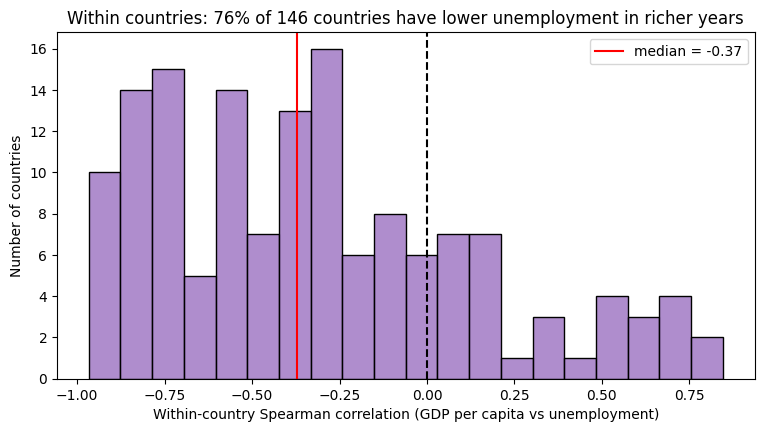

In [18]:
# Figure 4: within countries. For each country with at least 8 years of data, correlate its own
# GDP per capita with its own unemployment over time. Negative = unemployment lower in richer years.
def within_corr(g):
    g = g.dropna(subset=['log_gdp', 'unemployment_rate'])
    if len(g) < 8:
        return np.nan
    return g['log_gdp'].corr(g['unemployment_rate'], method='spearman')

within = df.groupby('Country Name').apply(within_corr, include_groups=False).dropna()
share_negative = (within < 0).mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(within, bins=20, ax=ax, color='tab:purple')
ax.axvline(0, color='black', ls='--')
ax.axvline(within.median(), color='red', label=f'median = {within.median():.2f}')
ax.set_xlabel('Within-country Spearman correlation (GDP per capita vs unemployment)')
ax.set_ylabel('Number of countries')
ax.set_title(f'Within countries: {share_negative:.0%} of {len(within)} countries have lower unemployment in richer years')
ax.legend()
plt.show()

### Answer (Question 2)

- **No. Across countries, higher GDP per capita does not mean lower unemployment.** The correlation is essentially zero (ρ = 0.05, p ≈ 0.5, 170 countries). The pattern is hump-shaped: median unemployment is lowest in the poorest (4.6%) and richest (5.6%) quartiles and highest in the middle (about 8.5%). Poor countries report low open unemployment because most people work informally and cannot afford to be unemployed.
- **Within a country, growth does go with lower unemployment.** In 76% of 146 countries, unemployment was lower in the years when GDP per capita was higher.
- **Decision:** do not use GDP per capita to rank or target countries for unemployment interventions; use labour-market indicators directly. For tracking a single country over time, rising GDP per capita is a reasonable rough signal that unemployment is easing.
- *Caveats:* unemployment uses national definitions; GDP in current US$ mixes real growth with inflation and exchange-rate effects, so the within-country result is only a rough signal.

## 4. Question 3: Do countries with higher GDP per capita tend to have longer life expectancy?

Same approach as Question 2: **between countries** (each country's 2000-2024 average), plus a check of how life expectancy differs across income groups. Uses `df` and `add_trend` from Question 1.

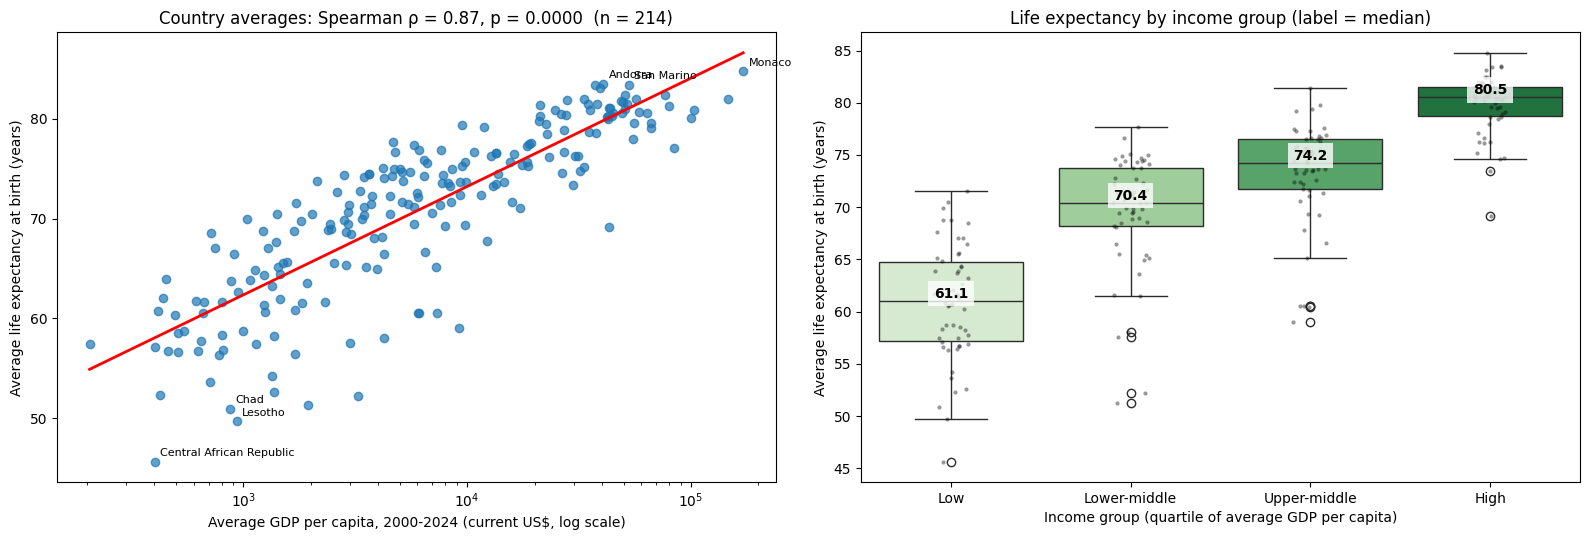

Each 10x increase in average GDP per capita goes with about 10.9 more years of life expectancy.
income_group
Low             61.1
Lower-middle    70.4
Upper-middle    74.2
High            80.5


In [19]:
# Figure 5: between countries. One point per country (2000-2024 averages); countries with
# fewer than 5 years of GDP data are dropped so averages are not based on one or two years.
n_gdp = df.groupby('Country Name')['gdp_per_capita'].count().rename('n_gdp')
avg_le = (df.groupby('Country Name')
            .agg(gdp_per_capita=('gdp_per_capita', 'mean'),
                 life_expectancy=('life_expectancy', 'mean'))
            .join(n_gdp))
avg_le = avg_le[avg_le['n_gdp'] >= 5].dropna(subset=['gdp_per_capita', 'life_expectancy']).copy()
avg_le['log_gdp'] = np.log10(avg_le['gdp_per_capita'])
avg_le['income_group'] = pd.qcut(avg_le['gdp_per_capita'], 4,
                                 labels=['Low', 'Lower-middle', 'Upper-middle', 'High'])

# Spearman correlation with a permutation p-value (shuffle life expectancy 10,000 times).
rng = np.random.default_rng(42)
rank_x, rank_y = avg_le['log_gdp'].rank().to_numpy(), avg_le['life_expectancy'].rank().to_numpy()
rho_le = np.corrcoef(rank_x, rank_y)[0, 1]
null = np.array([np.corrcoef(rank_x, rng.permutation(rank_y))[0, 1] for _ in range(10_000)])
p_le = (np.abs(null) >= abs(rho_le)).mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

ax = axes[0]
ax.scatter(avg_le['gdp_per_capita'], avg_le['life_expectancy'], alpha=0.7)
ax.set_xscale('log')
slope_le = add_trend(ax, avg_le['gdp_per_capita'], avg_le['life_expectancy'], log_x=True)
for name in avg_le['life_expectancy'].nsmallest(3).index.union(avg_le['life_expectancy'].nlargest(3).index):
    r = avg_le.loc[name]
    ax.annotate(name, (r['gdp_per_capita'], r['life_expectancy']), fontsize=8,
                xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('Average GDP per capita, 2000-2024 (current US$, log scale)')
ax.set_ylabel('Average life expectancy at birth (years)')
ax.set_title(f'Country averages: Spearman ρ = {rho_le:.2f}, p = {p_le:.4f}  (n = {len(avg_le)})')

ax = axes[1]
sns.boxplot(data=avg_le, x='income_group', y='life_expectancy',
            hue='income_group', legend=False, palette='Greens', ax=ax)
sns.stripplot(data=avg_le, x='income_group', y='life_expectancy', color='black', alpha=0.4, size=3, ax=ax)
medians_le = avg_le.groupby('income_group', observed=True)['life_expectancy'].median()
for i, m in enumerate(medians_le):
    ax.text(i, m, f'{m:.1f}', ha='center', va='bottom', fontweight='bold',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
ax.set_xlabel('Income group (quartile of average GDP per capita)')
ax.set_ylabel('Average life expectancy at birth (years)')
ax.set_title('Life expectancy by income group (label = median)')

plt.tight_layout()
plt.show()

print(f'Each 10x increase in average GDP per capita goes with about {slope_le:.1f} more years of life expectancy.')
print(medians_le.round(1).to_string())

### Answer (Question 3)

- **Yes. Countries with higher GDP per capita clearly tend to have longer life expectancy.** Each 10x increase in average GDP per capita goes with about 10.9 more years of life expectancy (the Spearman ρ and permutation p-value are in the Figure 5 title).
- **The gap shows up across every income group.** Median life expectancy rises steadily from 61.1 years in the poorest quartile to 70.4 (lower-middle), 74.2 (upper-middle) and 80.5 in the richest quartile. The biggest jump, about 9 years, is from the poorest to the lower-middle group, which fits the diminishing returns seen in Question 1.
- **Decision:** treat GDP per capita (on a log scale) as a reliable marker of population health. Gains in health are largest when moving out of the lowest income levels, so that is where income-related health interventions are likely to matter most.
- *Caveats:* correlation is not causation (health also raises productivity, and both depend on institutions and public services); GDP is in current US$ (not PPP); some countries sit well above or below the trend, which Question 8 looks at.

## 5. Question 4: Within each country, how do changes in GDP per capita relate to changes in unemployment?

Question 2 compared *levels* within a country. Here we use **year-over-year changes**: GDP growth (change in log GDP per capita, roughly the % growth) against the change in the unemployment rate (percentage points). Changes remove each country's fixed characteristics, so this asks whether unemployment falls in the years a country's GDP per capita grows. Uses `df` from Question 1.

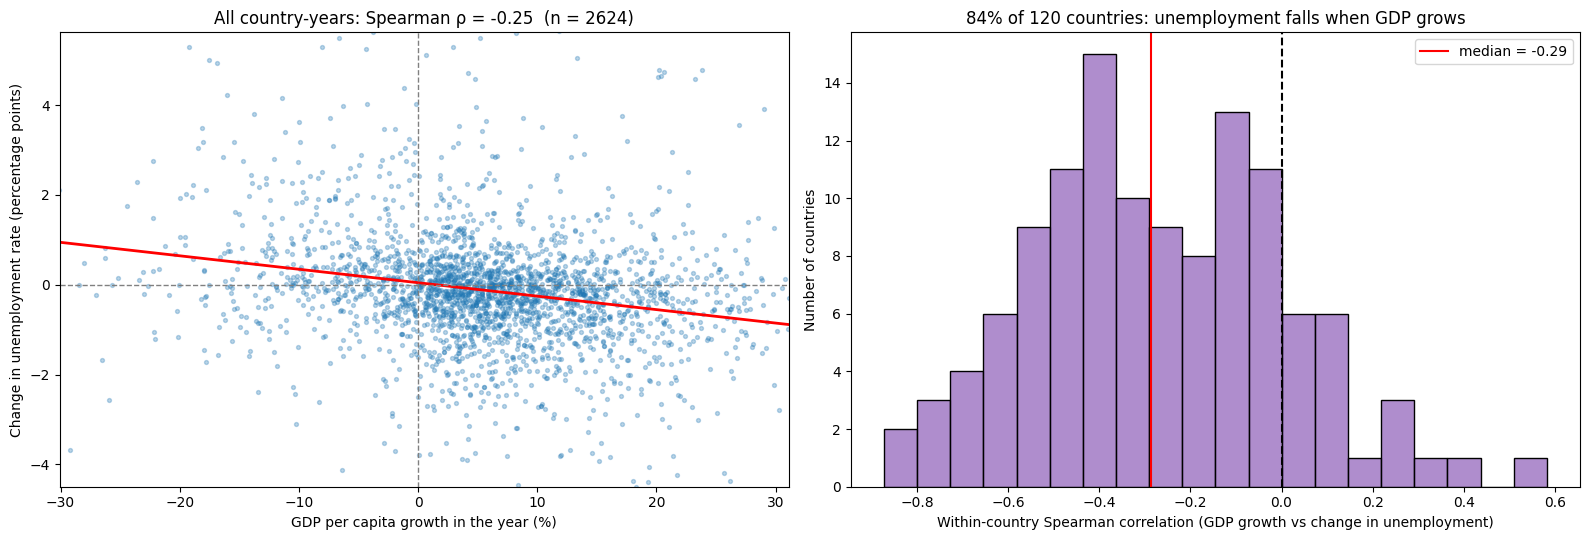

A 1 percentage-point higher GDP growth goes with a -0.030 percentage-point change in unemployment.
Median within-country correlation: -0.29; 48% of countries are below -0.3, 2% above +0.3.


In [20]:
# Figure 6: year-over-year changes within each country.
# Rows are sorted by year, so diff() only compares consecutive years (a missing year gives NaN).
chg = df.sort_values(['Country Name', 'year']).copy()
chg['gdp_growth_pct'] = chg.groupby('Country Name')['log_gdp'].diff() * np.log(10) * 100   # log10 -> % change
chg['d_unemployment'] = chg.groupby('Country Name')['unemployment_rate'].diff()            # percentage points
chg = chg.dropna(subset=['gdp_growth_pct', 'd_unemployment'])

# Pooled view: every country-year change in one plot (Spearman guards against outliers such as 2009 and 2020).
rho_pool = chg['gdp_growth_pct'].corr(chg['d_unemployment'], method='spearman')
slope_chg, intercept_chg = np.polyfit(chg['gdp_growth_pct'], chg['d_unemployment'], 1)

# Per-country view: correlation of each country's own yearly changes (at least 8 pairs of changes).
def within_chg_corr(g):
    return g['gdp_growth_pct'].corr(g['d_unemployment'], method='spearman') if len(g) >= 8 else np.nan

within_chg = chg.groupby('Country Name').apply(within_chg_corr, include_groups=False).dropna()
share_neg_chg = (within_chg < 0).mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

ax = axes[0]
ax.scatter(chg['gdp_growth_pct'], chg['d_unemployment'], s=8, alpha=0.3)
xs = np.linspace(chg['gdp_growth_pct'].quantile(0.01), chg['gdp_growth_pct'].quantile(0.99), 100)
ax.plot(xs, slope_chg * xs + intercept_chg, color='red', lw=2)
ax.axhline(0, color='grey', lw=1, ls='--')
ax.axvline(0, color='grey', lw=1, ls='--')
ax.set_xlim(chg['gdp_growth_pct'].quantile(0.01), chg['gdp_growth_pct'].quantile(0.99))
ax.set_ylim(chg['d_unemployment'].quantile(0.01), chg['d_unemployment'].quantile(0.99))
ax.set_xlabel('GDP per capita growth in the year (%)')
ax.set_ylabel('Change in unemployment rate (percentage points)')
ax.set_title(f'All country-years: Spearman ρ = {rho_pool:.2f}  (n = {len(chg)})')

ax = axes[1]
sns.histplot(within_chg, bins=20, ax=ax, color='tab:purple')
ax.axvline(0, color='black', ls='--')
ax.axvline(within_chg.median(), color='red', label=f'median = {within_chg.median():.2f}')
ax.set_xlabel('Within-country Spearman correlation (GDP growth vs change in unemployment)')
ax.set_ylabel('Number of countries')
ax.set_title(f'{share_neg_chg:.0%} of {len(within_chg)} countries: unemployment falls when GDP grows')
ax.legend()

plt.tight_layout()
plt.show()

print(f'A 1 percentage-point higher GDP growth goes with a {slope_chg:+.3f} percentage-point change in unemployment.')
print(f'Median within-country correlation: {within_chg.median():.2f}; '
      f'{(within_chg < -0.3).mean():.0%} of countries are below -0.3, {(within_chg > 0.3).mean():.0%} above +0.3.')

### Answer (Question 4)

- **Within a country, faster GDP growth goes with falling unemployment, but the link is modest.** The typical country has a within-country correlation of -0.29. Nearly half of countries (48%) are below -0.3, and only 2% are above +0.3, so almost no country shows unemployment rising systematically when GDP grows. The pooled Spearman ρ and the share of countries with a negative correlation are in the Figure 6 title.
- **The size of the effect per year is small.** Across all country-years, 1 percentage point more GDP per capita growth goes with only about 0.03 percentage points lower unemployment. Most year-to-year swings in unemployment are driven by other things.
- **This agrees with Question 2 but is weaker.** Comparing levels within a country (Question 2) gave a stronger link than comparing yearly changes does, because levels also pick up slow trends shared by both series.
- **Decision:** use GDP growth as a rough signal of the direction of unemployment within a country (growth years tend to be better, recession years worse), not to predict the size of the change. Labour-market indicators are needed for that.
- *Caveats:* GDP is in current US$, so growth mixes real growth with inflation and exchange-rate moves; unemployment changes usually lag GDP by a year or more, which same-year changes miss; shock years such as 2009 and 2020 can drive part of the pooled pattern.

## 6. Question 5: Within each country, how do changes in GDP per capita relate to changes in life expectancy?

Same approach as Question 4: **year-over-year changes** within each country (GDP growth in % against the change in life expectancy in years). Life expectancy rises slowly in most countries, so we also compare against the within-country relationship of *levels* to see how much of the link is just a shared long-run upward trend. Uses `df` from Question 1.

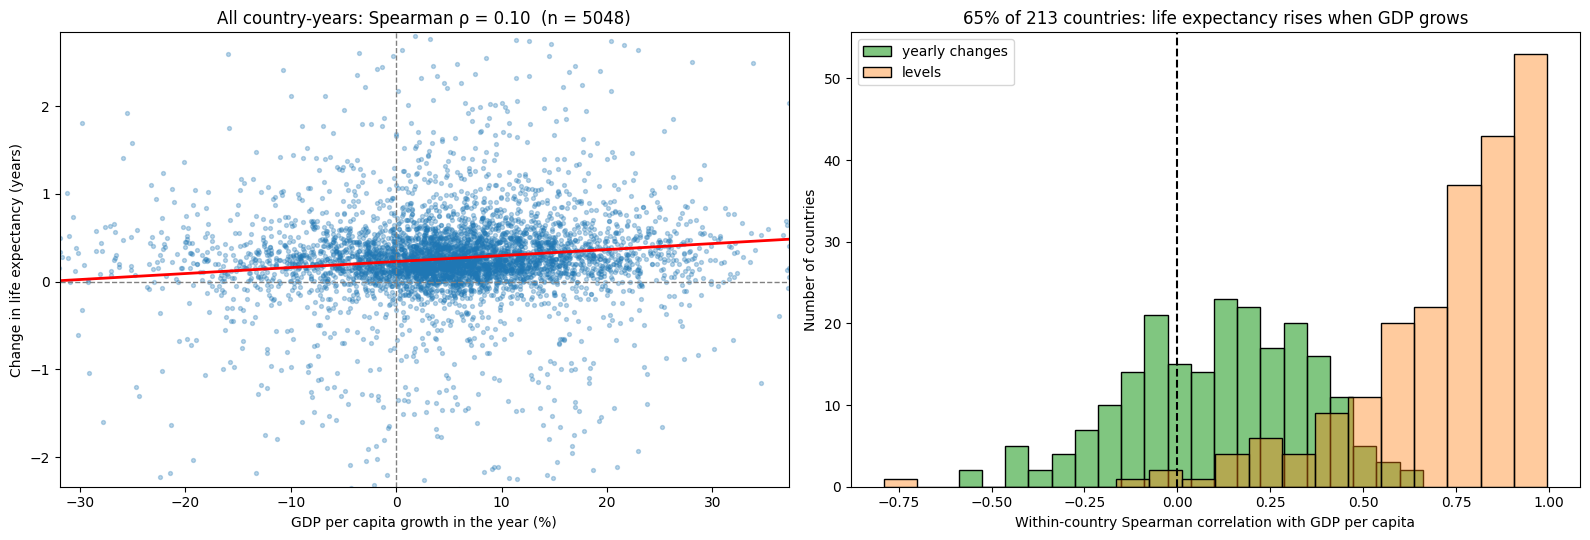

Pooled Spearman rho (changes) = 0.10, n = 5048; excluding 2020-2021: 0.09.
A 1 percentage-point higher GDP growth goes with a +0.007-year change in life expectancy.
Changes: median within-country rho = 0.12; 65% of 213 countries positive; 25% above +0.3, 5% below -0.3.
Levels:  median within-country rho = 0.79; 99% of 214 countries positive.


In [21]:
# Figure 7: year-over-year changes within each country (GDP growth vs change in life expectancy).
chg_le = df.sort_values(['Country Name', 'year']).copy()
chg_le['gdp_growth_pct'] = chg_le.groupby('Country Name')['log_gdp'].diff() * np.log(10) * 100   # log10 -> % change
chg_le['d_life_exp'] = chg_le.groupby('Country Name')['life_expectancy'].diff()                  # years
chg_le = chg_le.dropna(subset=['gdp_growth_pct', 'd_life_exp'])

rho_pool_le = chg_le['gdp_growth_pct'].corr(chg_le['d_life_exp'], method='spearman')
slope_chg_le, intercept_chg_le = np.polyfit(chg_le['gdp_growth_pct'], chg_le['d_life_exp'], 1)

def within_corr_le(g, x='gdp_growth_pct', y='d_life_exp'):
    return g[x].corr(g[y], method='spearman') if len(g) >= 8 else np.nan

within_chg_le = chg_le.groupby('Country Name').apply(within_corr_le, include_groups=False).dropna()
share_pos_chg_le = (within_chg_le > 0).mean()

# Comparison: within-country correlation of LEVELS (log GDP vs life expectancy over time).
within_lvl_le = (df.dropna(subset=['log_gdp', 'life_expectancy']).groupby('Country Name')
                   .apply(lambda g: within_corr_le(g, 'log_gdp', 'life_expectancy'), include_groups=False)
                   .dropna())

# Robustness: drop 2020-2021, when COVID-19 cut life expectancy and GDP at the same time.
chg_ex = chg_le[~chg_le['year'].isin([2020, 2021])]
rho_ex = chg_ex['gdp_growth_pct'].corr(chg_ex['d_life_exp'], method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

ax = axes[0]
ax.scatter(chg_le['gdp_growth_pct'], chg_le['d_life_exp'], s=8, alpha=0.3)
xs = np.linspace(chg_le['gdp_growth_pct'].quantile(0.01), chg_le['gdp_growth_pct'].quantile(0.99), 100)
ax.plot(xs, slope_chg_le * xs + intercept_chg_le, color='red', lw=2)
ax.axhline(0, color='grey', lw=1, ls='--')
ax.axvline(0, color='grey', lw=1, ls='--')
ax.set_xlim(chg_le['gdp_growth_pct'].quantile(0.01), chg_le['gdp_growth_pct'].quantile(0.99))
ax.set_ylim(chg_le['d_life_exp'].quantile(0.01), chg_le['d_life_exp'].quantile(0.99))
ax.set_xlabel('GDP per capita growth in the year (%)')
ax.set_ylabel('Change in life expectancy (years)')
ax.set_title(f'All country-years: Spearman ρ = {rho_pool_le:.2f}  (n = {len(chg_le)})')

ax = axes[1]
sns.histplot(within_chg_le, bins=20, ax=ax, color='tab:green', alpha=0.6, label='yearly changes')
sns.histplot(within_lvl_le, bins=20, ax=ax, color='tab:orange', alpha=0.4, label='levels')
ax.axvline(0, color='black', ls='--')
ax.set_xlabel('Within-country Spearman correlation with GDP per capita')
ax.set_ylabel('Number of countries')
ax.set_title(f'{share_pos_chg_le:.0%} of {len(within_chg_le)} countries: life expectancy rises when GDP grows')
ax.legend()

plt.tight_layout()
plt.show()

print(f'Pooled Spearman rho (changes) = {rho_pool_le:.2f}, n = {len(chg_le)}; excluding 2020-2021: {rho_ex:.2f}.')
print(f'A 1 percentage-point higher GDP growth goes with a {slope_chg_le:+.3f}-year change in life expectancy.')
print(f'Changes: median within-country rho = {within_chg_le.median():.2f}; {share_pos_chg_le:.0%} of {len(within_chg_le)} countries positive; '
      f'{(within_chg_le > 0.3).mean():.0%} above +0.3, {(within_chg_le < -0.3).mean():.0%} below -0.3.')
print(f'Levels:  median within-country rho = {within_lvl_le.median():.2f}; {(within_lvl_le > 0).mean():.0%} of {len(within_lvl_le)} countries positive.')

### Answer (Question 5)

- **Within a country, GDP and life expectancy move together over the long run, but year-to-year growth barely moves life expectancy.** Comparing levels, 99% of 214 countries have a positive correlation (median ρ = 0.79). Comparing yearly changes, the typical country has a median ρ of only 0.12, and the pooled correlation across 5,048 country-years is 0.10.
- **The direction is still mostly positive.** In 65% of 213 countries, life expectancy rose more in the years GDP per capita grew faster; 25% are above +0.3 and only 5% below -0.3.
- **The size per year is tiny.** 1 percentage point more GDP growth goes with only about 0.007 more years of life expectancy. Dropping 2020-2021 changes the pooled correlation only from 0.10 to 0.09, so COVID-19 does not drive the result.
- **Decision:** treat GDP per capita as a marker of a country's long-run health level, not as a lever for short-run changes. A good or bad growth year says little about that year's life expectancy; sustained income growth over many years is what goes with large health gains. Much of the strong levels result is likely both series trending upward together, so it should not be read as an effect of each year's growth.
- *Caveats:* correlation is not causation; GDP is in current US$ (growth mixes real growth, inflation and exchange rates); health effects of income can lag by years, which same-year changes miss.

## 7. Question 6: How is unemployment related to life expectancy?

Three views: **between countries** (2000-2024 averages), **between countries within the same income group** (because income could hide a link, as unemployment is hump-shaped in income, see Question 2), and **within countries** over time (levels and yearly changes). Uses `df` from Question 1.

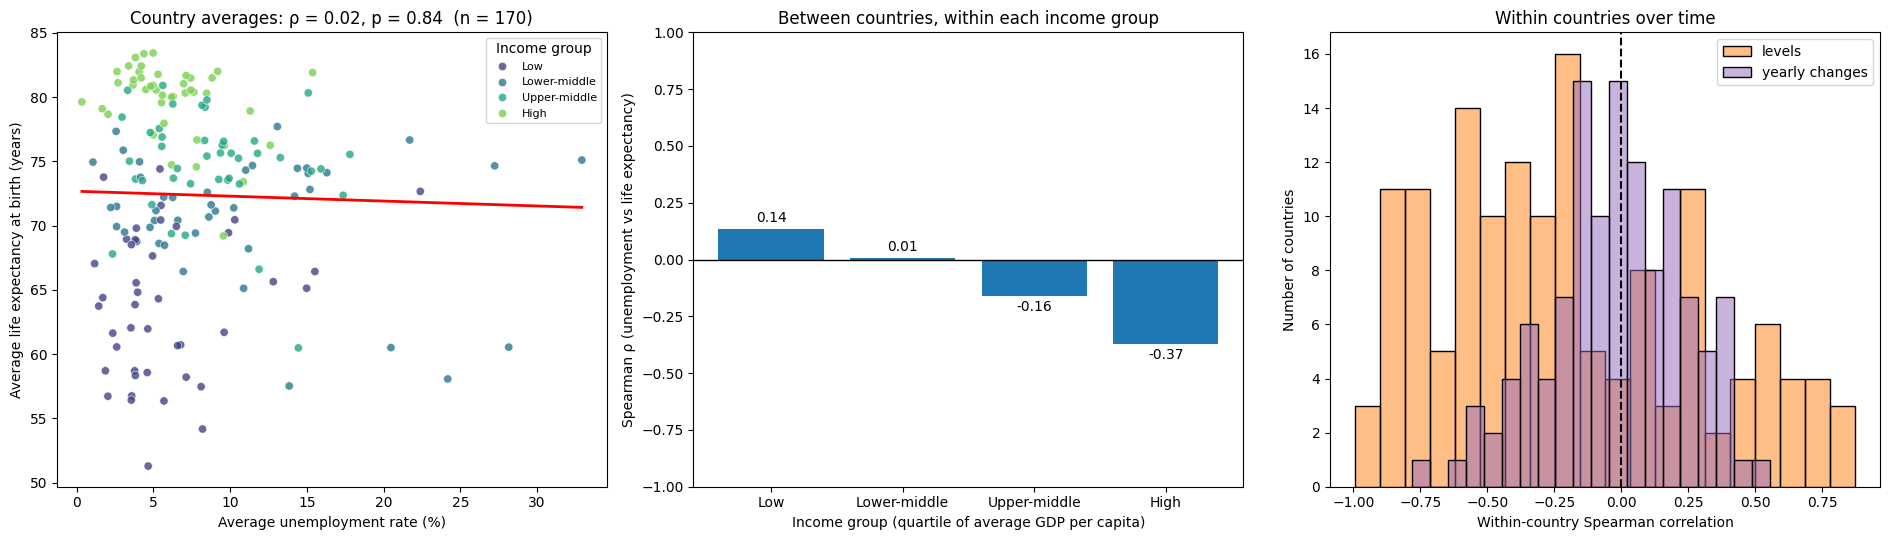

Between countries: rho = 0.02, p = 0.843, n = 170.
Within income groups: Low 0.14, Lower-middle 0.01, Upper-middle -0.16, High -0.37
Within countries, levels: median rho = -0.28; 32% of 146 countries positive.
Within countries, yearly changes: median rho = -0.01; 49% of 120 countries positive; pooled rho = -0.02 (n = 2639).


In [22]:
# Figure 8: unemployment vs life expectancy.
# (a) between countries: one point per country (2000-2024 averages, at least 5 years of unemployment data)
n_u = df.groupby('Country Name')['unemployment_rate'].count().rename('n_unemp')
avg_u = (df.groupby('Country Name')
           .agg(gdp_per_capita=('gdp_per_capita', 'mean'),
                unemployment_rate=('unemployment_rate', 'mean'),
                life_expectancy=('life_expectancy', 'mean'))
           .join(n_u))
avg_u = avg_u[avg_u['n_unemp'] >= 5].dropna().copy()
avg_u['income_group'] = pd.qcut(avg_u['gdp_per_capita'], 4,
                                labels=['Low', 'Lower-middle', 'Upper-middle', 'High'])

rank_x, rank_y = avg_u['unemployment_rate'].rank().to_numpy(), avg_u['life_expectancy'].rank().to_numpy()
rho_u = np.corrcoef(rank_x, rank_y)[0, 1]
rng = np.random.default_rng(42)
null = np.array([np.corrcoef(rank_x, rng.permutation(rank_y))[0, 1] for _ in range(10_000)])
p_u = (np.abs(null) >= abs(rho_u)).mean()

# (b) the same correlation inside each income group
by_group = avg_u.groupby('income_group', observed=True).apply(
    lambda g: g['unemployment_rate'].corr(g['life_expectancy'], method='spearman'), include_groups=False)

# (c) within countries over time: levels and yearly changes
def within_u(g, x, y):
    g = g.dropna(subset=[x, y])
    return g[x].corr(g[y], method='spearman') if len(g) >= 8 else np.nan

within_lvl_u = df.groupby('Country Name').apply(
    lambda g: within_u(g, 'unemployment_rate', 'life_expectancy'), include_groups=False).dropna()

chg_u = df.sort_values(['Country Name', 'year']).copy()
chg_u['d_unemployment'] = chg_u.groupby('Country Name')['unemployment_rate'].diff()
chg_u['d_life_exp'] = chg_u.groupby('Country Name')['life_expectancy'].diff()
chg_u = chg_u.dropna(subset=['d_unemployment', 'd_life_exp'])
within_chg_u = chg_u.groupby('Country Name').apply(
    lambda g: within_u(g, 'd_unemployment', 'd_life_exp'), include_groups=False).dropna()
rho_pool_u = chg_u['d_unemployment'].corr(chg_u['d_life_exp'], method='spearman')

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

ax = axes[0]
sns.scatterplot(data=avg_u, x='unemployment_rate', y='life_expectancy', hue='income_group',
                palette='viridis', ax=ax, alpha=0.8)
add_trend(ax, avg_u['unemployment_rate'], avg_u['life_expectancy'])
ax.set_xlabel('Average unemployment rate (%)')
ax.set_ylabel('Average life expectancy at birth (years)')
ax.set_title(f'Country averages: ρ = {rho_u:.2f}, p = {p_u:.2f}  (n = {len(avg_u)})')
ax.legend(title='Income group', fontsize=8)

ax = axes[1]
bars = ax.bar(by_group.index.astype(str), by_group.values, color='tab:blue')
ax.axhline(0, color='black', lw=1)
ax.bar_label(bars, fmt='%.2f', padding=3)
ax.set_ylim(-1, 1)
ax.set_xlabel('Income group (quartile of average GDP per capita)')
ax.set_ylabel('Spearman ρ (unemployment vs life expectancy)')
ax.set_title('Between countries, within each income group')

ax = axes[2]
sns.histplot(within_lvl_u, bins=20, ax=ax, color='tab:orange', alpha=0.5, label='levels')
sns.histplot(within_chg_u, bins=20, ax=ax, color='tab:purple', alpha=0.5, label='yearly changes')
ax.axvline(0, color='black', ls='--')
ax.set_xlabel('Within-country Spearman correlation')
ax.set_ylabel('Number of countries')
ax.set_title('Within countries over time')
ax.legend()

plt.tight_layout()
plt.show()

print(f'Between countries: rho = {rho_u:.2f}, p = {p_u:.3f}, n = {len(avg_u)}.')
print('Within income groups: ' + ', '.join(f'{k} {v:.2f}' for k, v in by_group.items()))
print(f'Within countries, levels: median rho = {within_lvl_u.median():.2f}; '
      f'{(within_lvl_u > 0).mean():.0%} of {len(within_lvl_u)} countries positive.')
print(f'Within countries, yearly changes: median rho = {within_chg_u.median():.2f}; '
      f'{(within_chg_u > 0).mean():.0%} of {len(within_chg_u)} countries positive; pooled rho = {rho_pool_u:.2f} (n = {len(chg_u)}).')

### Answer (Question 6)

- **Overall, unemployment and life expectancy are essentially unrelated.** Across 170 countries the correlation of country averages is ρ = 0.02 (p = 0.84). Year-to-year changes within countries show no link either: median ρ = -0.01, 49% of 120 countries positive, pooled ρ = -0.02 (n = 2,639). This matches Question 1.
- **Income hides a small pattern.** Within income groups the correlation moves from +0.14 (low) and +0.01 (lower-middle) to -0.16 (upper-middle) and -0.37 (high). Among the richest countries, higher unemployment goes with somewhat lower life expectancy; in poorer countries there is no such link. Each group has only about 40 countries, so the high-income result is suggestive, not firm.
- **Within countries, levels lean negative (median ρ = -0.28; only 32% of 146 countries positive), but yearly changes do not.** That gap suggests a shared long-run drift (life expectancy rising while unemployment fell in many countries) rather than unemployment shifts changing life expectancy year by year.
- **Decision:** do not use unemployment to predict or explain life expectancy across countries; income level and health-system factors matter far more. Any health cost of unemployment is worth testing only in high-income countries, with richer data.
- *Caveats:* unemployment uses national definitions and is available for only about 58% of country-years; correlation is not causation; unemployment in poorer countries understates joblessness because of informal work.

## 8. Question 7: Which countries have high GDP per capita but also high unemployment?

Definitions (on the 2000-2024 country averages, countries with at least 5 years of unemployment data): **high GDP per capita** = top quartile of average GDP per capita; **high unemployment** = above the 75th percentile of average unemployment across all countries. Because "high" depends on those cut-offs, we also list the rich countries ranked by unemployment. Uses `avg_u` from Question 6.

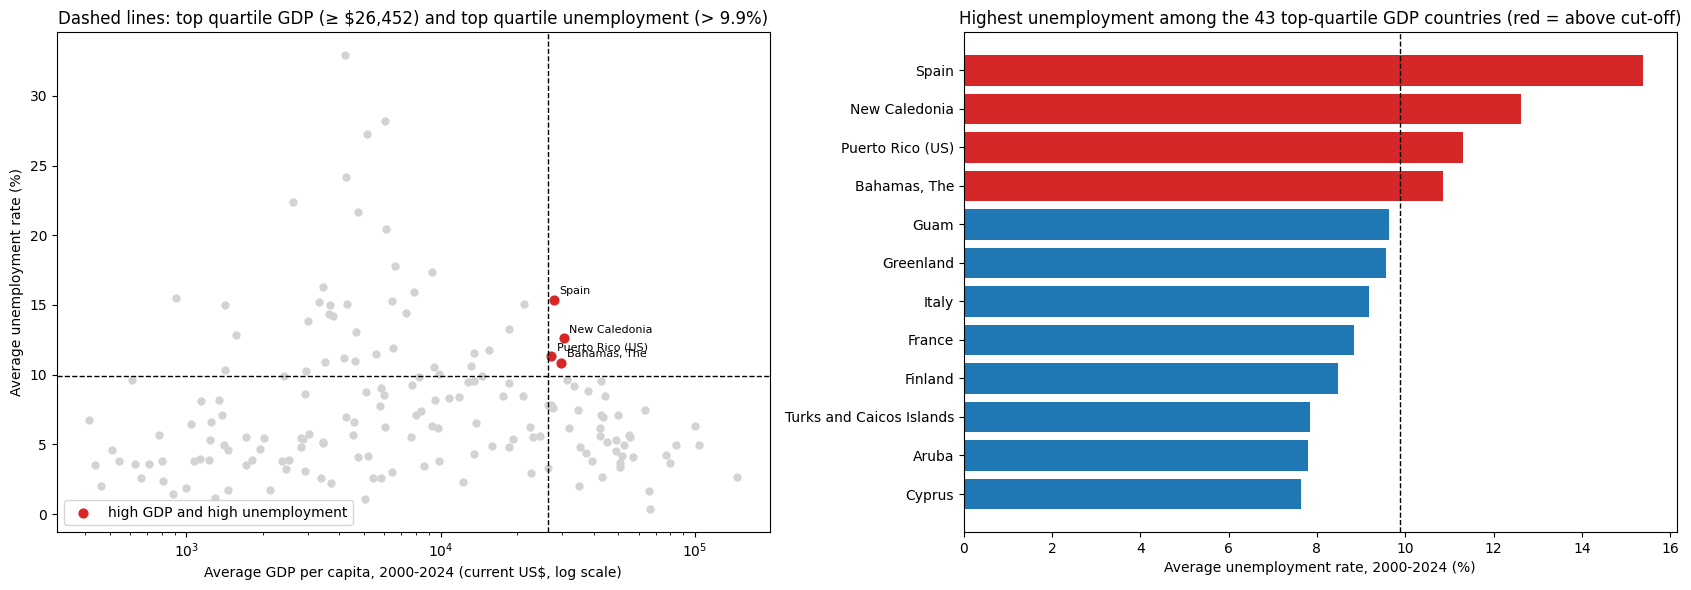

Cut-offs: GDP per capita >= $26,452, unemployment > 9.9%. 43 high-GDP countries, 4 of them with high unemployment.
                  gdp_per_capita  unemployment_rate  life_expectancy
Country Name                                                        
Spain                    27905.4               15.4             81.9
New Caledonia            30465.1               12.6             76.3
Puerto Rico (US)         27149.1               11.3             78.9
Bahamas, The             29739.9               10.9             73.4

Top 10 rich countries by unemployment:
                          gdp_per_capita  unemployment_rate
Country Name                                               
Spain                            27905.4               15.4
New Caledonia                    30465.1               12.6
Puerto Rico (US)                 27149.1               11.3
Bahamas, The                     29739.9               10.9
Guam                             31428.0                9.6
Greenland  

In [23]:
# Figure 9: rich countries with high unemployment.
gdp_cut = avg_u['gdp_per_capita'].quantile(0.75)
unemp_cut = avg_u['unemployment_rate'].quantile(0.75)
avg_u['high_gdp'] = avg_u['gdp_per_capita'] >= gdp_cut
avg_u['high_unemp'] = avg_u['unemployment_rate'] > unemp_cut
both = avg_u[avg_u['high_gdp'] & avg_u['high_unemp']].sort_values('unemployment_rate', ascending=False)
rich = avg_u[avg_u['high_gdp']].sort_values('unemployment_rate', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

ax = axes[0]
ax.scatter(avg_u['gdp_per_capita'], avg_u['unemployment_rate'], color='lightgrey', s=25)
ax.scatter(both['gdp_per_capita'], both['unemployment_rate'], color='tab:red', s=40, label='high GDP and high unemployment')
for name, r in both.iterrows():
    ax.annotate(name, (r['gdp_per_capita'], r['unemployment_rate']), fontsize=8,
                xytext=(4, 4), textcoords='offset points')
ax.axvline(gdp_cut, color='black', ls='--', lw=1)
ax.axhline(unemp_cut, color='black', ls='--', lw=1)
ax.set_xscale('log')
ax.set_xlabel('Average GDP per capita, 2000-2024 (current US$, log scale)')
ax.set_ylabel('Average unemployment rate (%)')
ax.set_title(f'Dashed lines: top quartile GDP (≥ ${gdp_cut:,.0f}) and top quartile unemployment (> {unemp_cut:.1f}%)')
ax.legend()

ax = axes[1]
top = rich.head(12).iloc[::-1]
ax.barh(top.index, top['unemployment_rate'], color=np.where(top['high_unemp'], 'tab:red', 'tab:blue'))
ax.axvline(unemp_cut, color='black', ls='--', lw=1)
ax.set_xlabel('Average unemployment rate, 2000-2024 (%)')
ax.set_title(f'Highest unemployment among the {len(rich)} top-quartile GDP countries (red = above cut-off)')

plt.tight_layout()
plt.show()

print(f'Cut-offs: GDP per capita >= ${gdp_cut:,.0f}, unemployment > {unemp_cut:.1f}%. '
      f'{len(rich)} high-GDP countries, {len(both)} of them with high unemployment.')
print(both[['gdp_per_capita', 'unemployment_rate', 'life_expectancy']].round(1).to_string())
print('\nTop 10 rich countries by unemployment:')
print(rich[['gdp_per_capita', 'unemployment_rate']].head(10).round(1).to_string())

### Answer (Question 7)

- **Only 4 of the 43 high-GDP countries also have high unemployment** (GDP per capita of at least $26,452 and average unemployment above 9.9%, 2000-2024): **Spain** (15.4%), **New Caledonia** (12.6%), **Puerto Rico** (11.3%) and **The Bahamas** (10.9%). So rich and high-unemployment is the exception, not the rule, which fits the near-zero link found in Question 2.
- **Spain is the clear standout.** It has the highest unemployment of any rich country by a wide margin (15.4% against 12.6% for the next), and the only large, mainstream economy on the list. Its life expectancy is also high (81.9 years), so high unemployment here does not come with poor health, in line with Question 6.
- **The other three are small territories or island economies** (New Caledonia, Puerto Rico, The Bahamas), where small, tourism- or transfer-dependent economies can combine high income with high joblessness. Their life expectancy is lower (73.4 to 78.9 years).
- **Just below the cut-off** are Guam and Greenland (both 9.6%), Italy (9.2%) and France (8.8%), so the list is sensitive to where the line is drawn. Among the larger economies, the southern European pattern (Spain, Italy, France) is the main case.
- **Decision:** when targeting labour-market policy, look at country-specific causes (for example Spain's labour market) rather than assuming rich countries have low unemployment or that income protects against it.
- *Caveats:* "high" depends on quartile cut-offs; averages over 2000-2024 hide large swings (for example Spain's peak after 2008); unemployment uses national definitions; the reasons given for the island economies are plausible explanations I did not test.

## 9. Question 8: Which countries have low GDP per capita but relatively high life expectancy?

Definitions (on the 2000-2024 country averages from Question 3): **low GDP per capita** = bottom quartile of average GDP per capita. **Relatively high life expectancy** is measured two ways: (1) the gap between a country's life expectancy and what the all-country trend (life expectancy against log GDP) predicts for its income, and (2) whether it exceeds the median life expectancy of all countries. Uses `avg_le` from Question 3.

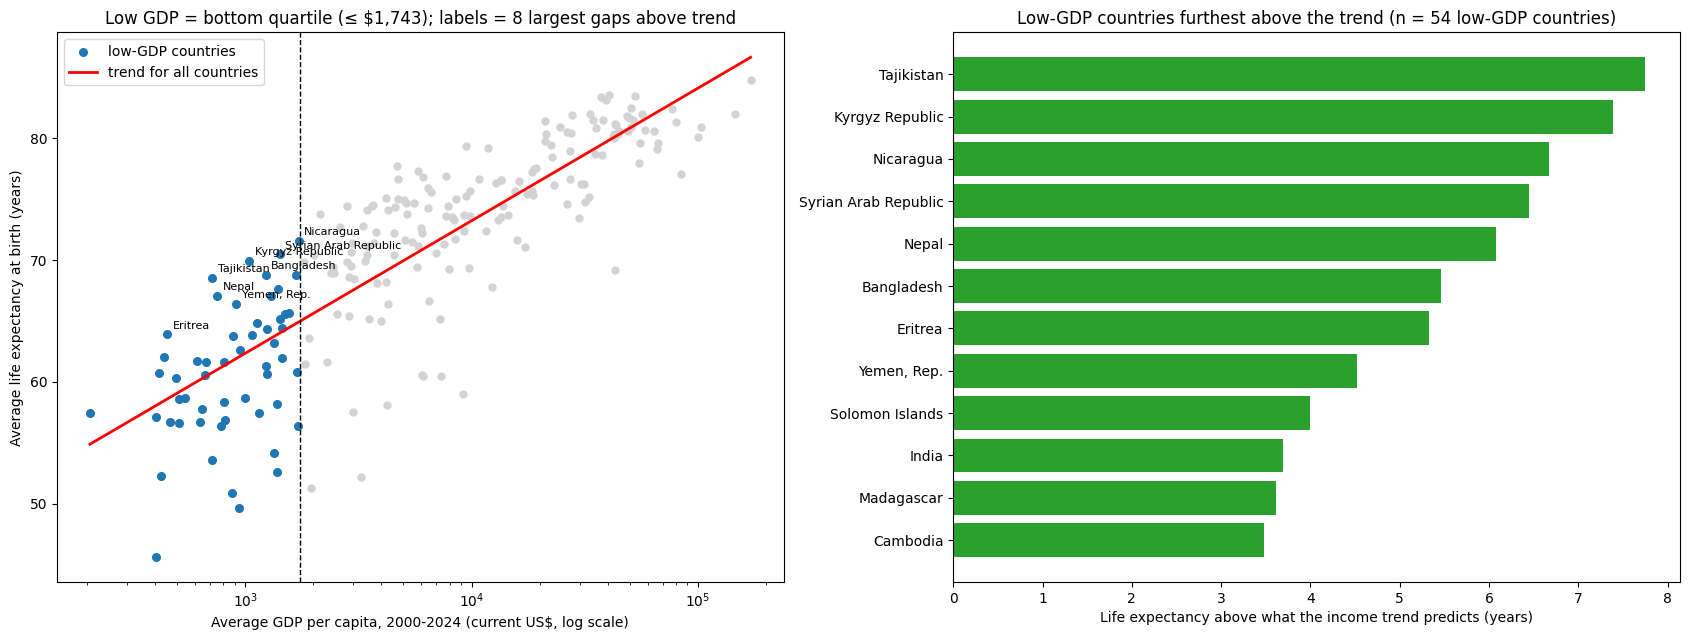

Low-GDP cut-off: <= $1,743 (54 countries). Median life expectancy, all countries: 72.4 years.
Low-GDP countries above the all-country median life expectancy: 0.

Top 12 low-GDP countries by gap above the trend:
                      gdp_per_capita  life_expectancy  expected_le  gap
Country Name                                                           
Tajikistan                     715.6             68.5         60.8  7.8
Kyrgyz Republic               1044.3             69.9         62.6  7.4
Nicaragua                     1720.0             71.6         64.9  6.7
Syrian Arab Republic          1422.0             70.5         64.0  6.4
Nepal                          751.6             67.1         61.0  6.1
Bangladesh                    1229.9             68.8         63.3  5.5
Eritrea                        451.9             63.9         58.6  5.3
Yemen, Rep.                    911.8             66.4         61.9  4.5
Solomon Islands               1678.0             68.8         64.8  4

In [24]:
# Figure 10: low-income countries that live longer than their income predicts.
slope_o, intercept_o = np.polyfit(avg_le['log_gdp'], avg_le['life_expectancy'], 1)
avg_le['expected_le'] = slope_o * avg_le['log_gdp'] + intercept_o
avg_le['gap'] = avg_le['life_expectancy'] - avg_le['expected_le']          # years above (+) / below (-) the trend

gdp_cut_low = avg_le['gdp_per_capita'].quantile(0.25)
median_le = avg_le['life_expectancy'].median()
low = avg_le[avg_le['gdp_per_capita'] <= gdp_cut_low].sort_values('gap', ascending=False)
above_median = low[low['life_expectancy'] > median_le]

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

ax = axes[0]
ax.scatter(avg_le['gdp_per_capita'], avg_le['life_expectancy'], color='lightgrey', s=25)
ax.scatter(low['gdp_per_capita'], low['life_expectancy'], color='tab:blue', s=30, label='low-GDP countries')
xs = np.linspace(avg_le['log_gdp'].min(), avg_le['log_gdp'].max(), 100)
ax.plot(10 ** xs, slope_o * xs + intercept_o, color='red', lw=2, label='trend for all countries')
for name, r in low.head(8).iterrows():
    ax.annotate(name, (r['gdp_per_capita'], r['life_expectancy']), fontsize=8,
                xytext=(4, 4), textcoords='offset points')
ax.axvline(gdp_cut_low, color='black', ls='--', lw=1)
ax.set_xscale('log')
ax.set_xlabel('Average GDP per capita, 2000-2024 (current US$, log scale)')
ax.set_ylabel('Average life expectancy at birth (years)')
ax.set_title(f'Low GDP = bottom quartile (≤ ${gdp_cut_low:,.0f}); labels = 8 largest gaps above trend')
ax.legend()

ax = axes[1]
top = low.head(12).iloc[::-1]
ax.barh(top.index, top['gap'], color='tab:green')
ax.set_xlabel('Life expectancy above what the income trend predicts (years)')
ax.set_title(f'Low-GDP countries furthest above the trend (n = {len(low)} low-GDP countries)')

plt.tight_layout()
plt.show()

print(f'Low-GDP cut-off: <= ${gdp_cut_low:,.0f} ({len(low)} countries). Median life expectancy, all countries: {median_le:.1f} years.')
print(f'Low-GDP countries above the all-country median life expectancy: {len(above_median)}.')
print('\nTop 12 low-GDP countries by gap above the trend:')
print(low[['gdp_per_capita', 'life_expectancy', 'expected_le', 'gap']].head(12).round(1).to_string())
print('\nLow-GDP countries above the all-country median life expectancy:')
print(above_median[['gdp_per_capita', 'life_expectancy', 'gap']].round(1).to_string())

### Answer (Question 8)

- **No low-GDP country beats the all-country median life expectancy (72.4 years).** Of the 54 countries in the bottom GDP quartile (average GDP per capita of $1,743 or less, 2000-2024), none exceeds it. Income still sets a ceiling, in line with Question 3. "Relatively high" therefore has to mean *higher than their income predicts*.
- **The countries furthest above the trend are in Central and South Asia, with a few elsewhere.** Tajikistan (68.5 years, 7.8 above the trend), the Kyrgyz Republic (69.9, +7.4), Nicaragua (71.6, +6.7), Syria (70.5, +6.4), Nepal (67.1, +6.1) and Bangladesh (68.8, +5.5) lead, followed by Eritrea, Yemen, the Solomon Islands, India, Madagascar and Cambodia (+3.5 to +5.3). The best of these reach about 70 years on an income of roughly $700-$1,700 per person, where the trend predicts 61-65.
- **Decision:** these countries are the best places to look for low-cost health gains that income alone does not explain. Check what they do differently (for example basic primary care, vaccination, sanitation or nutrition programmes) before assuming low income means low life expectancy.
- *Caveats:* the "trend" is a straight line on log GDP, so gaps partly reflect its shape; averages over 2000-2024 hide big changes (Syria's life expectancy fell sharply during the war, so its average is pulled down); GDP is in current US$ (not PPP), which understates living standards in low-price countries; why these countries do well is not tested here.

## 10. Question 9: Did these relationships differ between 2000-2019 and 2020-2024?

We recompute the relationships from Questions 1-6 separately for the two periods: the three **cross-country (levels)** correlations, and the three **within-country yearly-change** correlations (a change is assigned to the later year, so 2020 compares 2019 with 2020). 2020-2024 is only five years, so each correlation gets a 95% interval from resampling countries 500 times; a difference only counts if the intervals clearly separate. Uses `df` from Question 1.

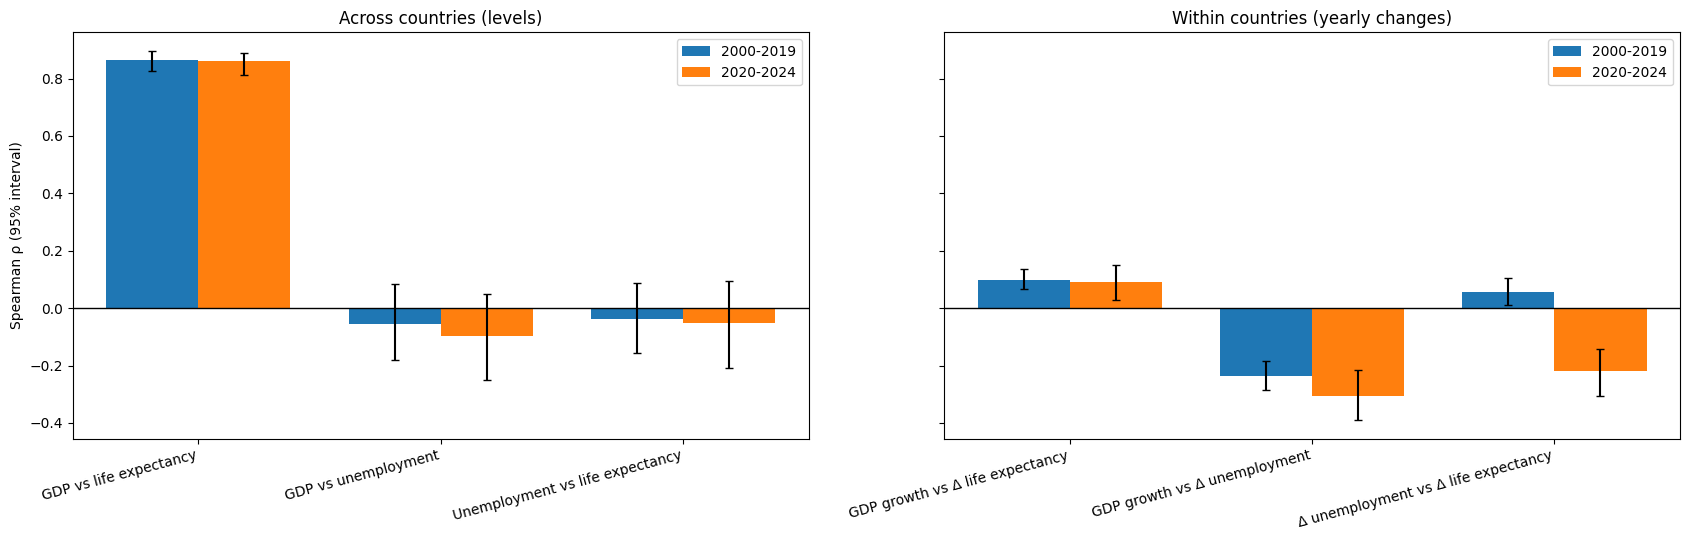

   kind                                pair    period   rho    lo    hi    n
 levels              GDP vs life expectancy 2000-2019  0.87  0.83  0.90 4229
 levels                 GDP vs unemployment 2000-2019 -0.05 -0.18  0.08 2567
 levels     Unemployment vs life expectancy 2000-2019 -0.04 -0.16  0.09 2584
changes     GDP growth vs Δ life expectancy 2000-2019  0.10  0.07  0.14 4011
changes        GDP growth vs Δ unemployment 2000-2019 -0.24 -0.29 -0.19 2099
changes Δ unemployment vs Δ life expectancy 2000-2019  0.06  0.01  0.10 2114
 levels              GDP vs life expectancy 2020-2024  0.86  0.81  0.89 1038
 levels                 GDP vs unemployment 2020-2024 -0.10 -0.25  0.05  593
 levels     Unemployment vs life expectancy 2020-2024 -0.05 -0.21  0.09  593
changes     GDP growth vs Δ life expectancy 2020-2024  0.09  0.03  0.15 1037
changes        GDP growth vs Δ unemployment 2020-2024 -0.31 -0.39 -0.22  525
changes Δ unemployment vs Δ life expectancy 2020-2024 -0.22 -0.30 -0.14  525

In [25]:
# Figure 11: relationships in 2000-2019 vs 2020-2024.
panel = df.sort_values(['Country Name', 'year']).copy()
panel['gdp_growth_pct'] = panel.groupby('Country Name')['log_gdp'].diff() * np.log(10) * 100
panel['d_unemployment'] = panel.groupby('Country Name')['unemployment_rate'].diff()
panel['d_life_exp'] = panel.groupby('Country Name')['life_expectancy'].diff()
panel['period'] = np.where(panel['year'] <= 2019, '2000-2019', '2020-2024')

specs = {
    'levels': [('log_gdp', 'life_expectancy', 'GDP vs life expectancy'),
               ('log_gdp', 'unemployment_rate', 'GDP vs unemployment'),
               ('unemployment_rate', 'life_expectancy', 'Unemployment vs life expectancy')],
    'changes': [('gdp_growth_pct', 'd_life_exp', 'GDP growth vs Δ life expectancy'),
                ('gdp_growth_pct', 'd_unemployment', 'GDP growth vs Δ unemployment'),
                ('d_unemployment', 'd_life_exp', 'Δ unemployment vs Δ life expectancy')]}

def spearman(d, x, y):
    d = d[[x, y]].dropna()
    return d[x].corr(d[y], method='spearman') if len(d) > 10 else np.nan

rng = np.random.default_rng(42)
rows = []
for period, p in panel.groupby('period'):
    groups = {k: g for k, g in p.groupby('Country Name')}
    names = np.array(list(groups))
    boots = [pd.concat([groups[n] for n in rng.choice(names, len(names))]) for _ in range(500)]
    for kind, items in specs.items():
        for x, y, label in items:
            vals = [spearman(b, x, y) for b in boots]
            lo, hi = np.nanpercentile(vals, [2.5, 97.5])
            rows.append(dict(kind=kind, pair=label, period=period, rho=spearman(p, x, y), lo=lo, hi=hi,
                             n=len(p[[x, y]].dropna())))
res = pd.DataFrame(rows)

# Slope of life expectancy on log10(GDP) across countries, per period (years per 10x GDP)
slopes = {}
for period, p in panel.groupby('period'):
    d = p[['log_gdp', 'life_expectancy']].dropna()
    slopes[period] = np.polyfit(d['log_gdp'], d['life_expectancy'], 1)[0]

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), sharey=True)
for ax, kind, title in zip(axes, ['levels', 'changes'],
                           ['Across countries (levels)', 'Within countries (yearly changes)']):
    sub = res[res['kind'] == kind]
    pairs_k = sub['pair'].unique()
    xpos = np.arange(len(pairs_k))
    for i, (period, color) in enumerate(zip(['2000-2019', '2020-2024'], ['tab:blue', 'tab:orange'])):
        s = sub[sub['period'] == period].set_index('pair').loc[pairs_k]
        ax.bar(xpos + (i - 0.5) * 0.38, s['rho'], width=0.38, color=color, label=period,
               yerr=[s['rho'] - s['lo'], s['hi'] - s['rho']], capsize=3)
    ax.axhline(0, color='black', lw=1)
    ax.set_xticks(xpos)
    ax.set_xticklabels(pairs_k, rotation=15, ha='right')
    ax.set_title(title)
    ax.legend()
axes[0].set_ylabel('Spearman ρ (95% interval)')
plt.tight_layout()
plt.show()

print(res.round(2).to_string(index=False))
print(f"\nYears of life expectancy per 10x GDP per capita: 2000-2019 = {slopes['2000-2019']:.1f}, 2020-2024 = {slopes['2020-2024']:.1f}")
print('Mean life expectancy change per year: ' + ', '.join(
    f'{k} = {v:+.2f}' for k, v in panel.groupby('period')['d_life_exp'].mean().items()))
print('Mean GDP growth per year (%): ' + ', '.join(
    f'{k} = {v:+.1f}' for k, v in panel.groupby('period')['gdp_growth_pct'].mean().items()))

### Answer (Question 9)

- **Mostly no. The main relationships look the same in both periods.** Across countries, GDP and life expectancy stay strongly linked (ρ = 0.87 in 2000-2019, 0.86 in 2020-2024, with heavily overlapping intervals), and each 10x increase in GDP per capita goes with about 10.7 years of life expectancy before 2020 and 9.9 after. GDP vs unemployment (-0.05 and -0.10) and unemployment vs life expectancy (-0.04 and -0.05) are close to zero in both periods, and their intervals include zero.
- **Within countries, GDP growth tells the same story in both periods.** Growth vs the change in life expectancy is weak and positive (0.10 and 0.09). Growth vs the change in unemployment is negative in both (-0.24 and -0.31); the second is slightly stronger, but the intervals overlap, so this is not a clear difference.
- **One relationship clearly changed: yearly changes in unemployment vs life expectancy.** It was close to zero before 2020 (ρ = 0.06, interval 0.01 to 0.10) and became negative after (ρ = -0.22, interval -0.30 to -0.14). In 2020-2024, years when unemployment rose tended to be years when life expectancy fell, and the other way round. This likely reflects the COVID-19 shock hitting both at once, but that explanation is not tested here.
- **Progress was slower in the second period.** The average yearly gain in life expectancy slowed from +0.29 to +0.20 years, and average yearly GDP per capita growth from 5.4% to 3.8%.
- **Decision:** the conclusions from Questions 1-8 hold in both periods and can be used for the whole 2000-2024 span. Treat the post-2019 link between unemployment and life expectancy as a shock-period effect and avoid generalising it.
- *Caveats:* 2020-2024 has only five years and intervals from resampling countries are approximate; the same countries appear in both periods, so overlapping intervals are a rough guide rather than a formal test; the slope difference (10.7 vs 9.9) was not tested.

## 11. Question 10: How do the three indicators differ across continents?

The dataset has no continent column, so we add one by mapping each country's World Bank code to a continent (Middle Eastern countries are counted in Asia; Greenland, the Caribbean and Central America in North America). We then compare the **country averages for 2000-2024** across continents, using the same minimum of 5 years of data per country as in earlier questions, and test whether the differences are larger than chance with a Kruskal-Wallis test (rank-based, so it is not distorted by skewed GDP). Uses `df` from Question 1; the `continent` column added here is reused in Questions 11-12.

Countries without a continent (dropped from this question): ['Fragility, Conflict, and Violence (FCV) situations']


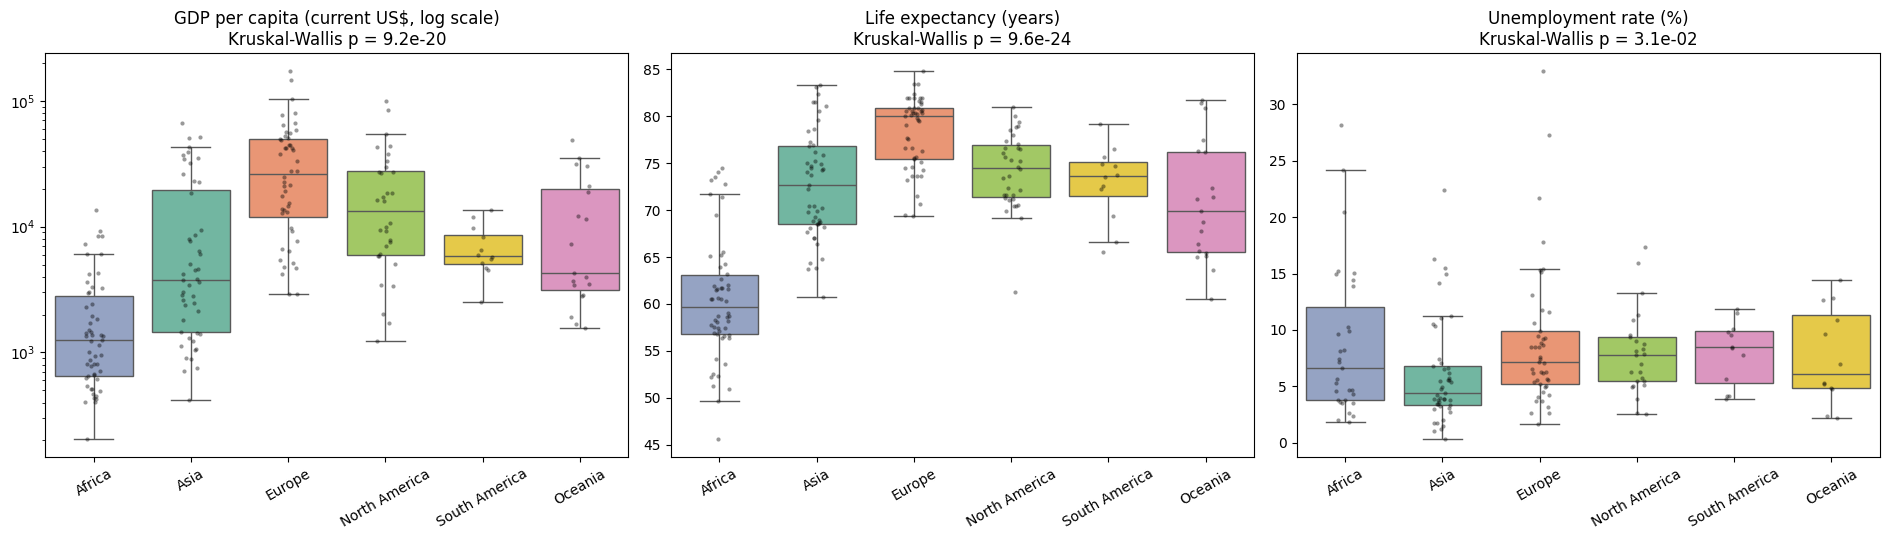

                n  gdp_median  life_exp_median  unemp_median
continent                                                   
Africa         54      1245.0             59.7           6.6
Asia           48      3798.0             72.7           4.4
Europe         48     26103.0             80.0           7.1
North America  32     13317.0             74.5           7.8
South America  12      5862.0             73.7           8.4
Oceania        19      4257.0             69.9           6.1
gdp_per_capita: Kruskal-Wallis p = 9.15e-20
life_expectancy: Kruskal-Wallis p = 9.60e-24
unemployment_rate: Kruskal-Wallis p = 3.10e-02


In [26]:
# Figure 12: the three indicators by continent.
from scipy.stats import kruskal

continent_codes = {
    'Africa': 'DZA AGO BEN BWA BFA BDI CPV CMR CAF TCD COM COD COG CIV DJI EGY GNQ ERI SWZ ETH GAB GMB GHA GIN GNB '
              'KEN LSO LBR LBY MDG MWI MLI MRT MUS MAR MOZ NAM NER NGA RWA STP SEN SYC SLE SOM ZAF SSD SDN TZA TGO '
              'TUN UGA ZMB ZWE',
    'Asia': 'AFG ARM AZE BHR BGD BTN BRN KHM CHN GEO HKG IND IDN IRN IRQ ISR JPN JOR KAZ KWT KGZ LAO LBN MAC MYS '
            'MDV MNG MMR NPL PRK OMN PAK PSE PHL QAT SAU SGP KOR LKA SYR TJK THA TLS TUR TKM ARE UZB VNM YEM',
    'Europe': 'ALB AND AUT BLR BEL BIH BGR HRV CYP CZE DNK EST FRO FIN FRA DEU GIB GRC HUN ISL IRL IMN ITA XKX LVA '
              'LIE LTU LUX MLT MDA MCO MNE NLD MKD NOR POL PRT ROU RUS SMR SRB SVK SVN ESP SWE CHE UKR GBR CHI',
    'North America': 'ATG BHS BRB BLZ BMU CAN CYM CRI CUB CUW DMA DOM SLV GRL GRD GTM HTI HND JAM MEX NIC PAN PRI '
                     'KNA LCA MAF VCT SXM TTO TCA USA VGB VIR ABW',
    'South America': 'ARG BOL BRA CHL COL ECU GUY PRY PER SUR URY VEN',
    'Oceania': 'ASM AUS FJI PYF GUM KIR MHL FSM NRU NCL NZL MNP PLW PNG WSM SLB TON TUV VUT'}
continent_of = {code: cont for cont, codes in continent_codes.items() for code in codes.split()}
df['continent'] = df['Country Code'].map(continent_of)

unmapped = sorted(df.loc[df['continent'].isna(), 'Country Name'].unique())
print(f'Countries without a continent (dropped from this question): {unmapped if unmapped else "none"}')

# Country averages, 2000-2024; each indicator needs at least 5 years of data per country.
cont_order = ['Africa', 'Asia', 'Europe', 'North America', 'South America', 'Oceania']
cc = df.dropna(subset=['continent']).groupby(['Country Name', 'continent'])
by_country = pd.DataFrame({
    'gdp_per_capita': cc['gdp_per_capita'].mean().where(cc['gdp_per_capita'].count() >= 5),
    'life_expectancy': cc['life_expectancy'].mean().where(cc['life_expectancy'].count() >= 5),
    'unemployment_rate': cc['unemployment_rate'].mean().where(cc['unemployment_rate'].count() >= 5),
}).reset_index()

titles = {'gdp_per_capita': 'GDP per capita (current US$, log scale)',
          'life_expectancy': 'Life expectancy (years)',
          'unemployment_rate': 'Unemployment rate (%)'}
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
summary = {}
for ax, col in zip(axes, titles):
    d = by_country.dropna(subset=[col])
    sns.boxplot(data=d, x='continent', y=col, order=cont_order, hue='continent', legend=False,
                palette='Set2', ax=ax, showfliers=False)
    sns.stripplot(data=d, x='continent', y=col, order=cont_order, color='black', alpha=0.4, size=3, ax=ax)
    if col == 'gdp_per_capita':
        ax.set_yscale('log')
    p = kruskal(*[g[col].values for _, g in d.groupby('continent')]).pvalue
    ax.set_title(f'{titles[col]}\nKruskal-Wallis p = {p:.1e}')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=30)
    summary[col] = d.groupby('continent')[col].agg(['count', 'median']).reindex(cont_order)
plt.tight_layout()
plt.show()

table = pd.concat({'n': summary['gdp_per_capita']['count'].astype(int),
                   'gdp_median': summary['gdp_per_capita']['median'].round(0),
                   'life_exp_median': summary['life_expectancy']['median'].round(1),
                   'unemp_median': summary['unemployment_rate']['median'].round(1)}, axis=1)
print(table.to_string())
for col in titles:
    d = by_country.dropna(subset=[col])
    print(f'{col}: Kruskal-Wallis p = {kruskal(*[g[col].values for _, g in d.groupby("continent")]).pvalue:.2e}')

### Answer (Question 10)

- **Continents differ hugely in income and life expectancy, but much less in unemployment.** Both GDP per capita and life expectancy differ strongly (Kruskal-Wallis p ≈ 9e-20 and 1e-23); unemployment differs only weakly (p = 0.03).
- **GDP per capita (median of country averages):** Europe is highest at about $26,100, then North America ($13,300), South America ($5,900), Oceania ($4,300), Asia ($3,800) and Africa lowest at about $1,200. Europe's median is roughly 20 times Africa's.
- **Life expectancy (median years):** Europe 80.0, North America 74.5, South America 73.7, Asia 72.7, Oceania 69.9 and Africa 59.7. Africa trails Europe by about 20 years and the next-lowest continent by about 10.
- **Unemployment (median %):** Asia is lowest (4.4), then Oceania (6.1), Africa (6.6), Europe (7.1), North America (7.8) and South America highest (8.4). The ranking does not follow income: Africa, the poorest, sits in the middle and Europe, the richest, is above Asia and Oceania. This fits Question 2 (no clear link between income and unemployment).
- **Income does not explain everything:** Oceania has higher median GDP than Asia ($4,300 vs $3,800) but lower life expectancy (69.9 vs 72.7 years). Why is not tested here.
- **Decision:** use continent as a rough guide to income and health (Africa stands out as lowest on both) but not to unemployment, where the gaps between continents are small (4.4% to 8.4% in the medians) and only weakly significant.
- *Caveats:* these are medians of country averages, so each country counts equally whatever its population; South America has only 12 countries and Oceania mostly small island states; the Kruskal-Wallis test shows continents differ but not which pairs do; the unemployment p-value (0.03) would not survive correcting for the three tests run; continents were assigned by a hand-made country-code mapping, and 213 countries have GDP data here, fewer than the 218 in the full data (the printed list of unmapped countries was not checked).

## 12. Question 11: Is the GDP-life expectancy relationship stronger in some continents than others?

Within each continent we measure the relationship three ways: the **Spearman correlation** across countries (2000-2024 averages), the **slope** (extra years of life expectancy per 10x GDP per capita), and the **within-country yearly-change correlation** from Question 5. Continents with few countries (for example South America, 12) give uncertain estimates, so every number gets a 95% interval from resampling countries 1,000 times; a difference between continents only counts if the intervals clearly separate. Uses `by_country` and `continent_of` from Question 10 and `panel` from Question 9.

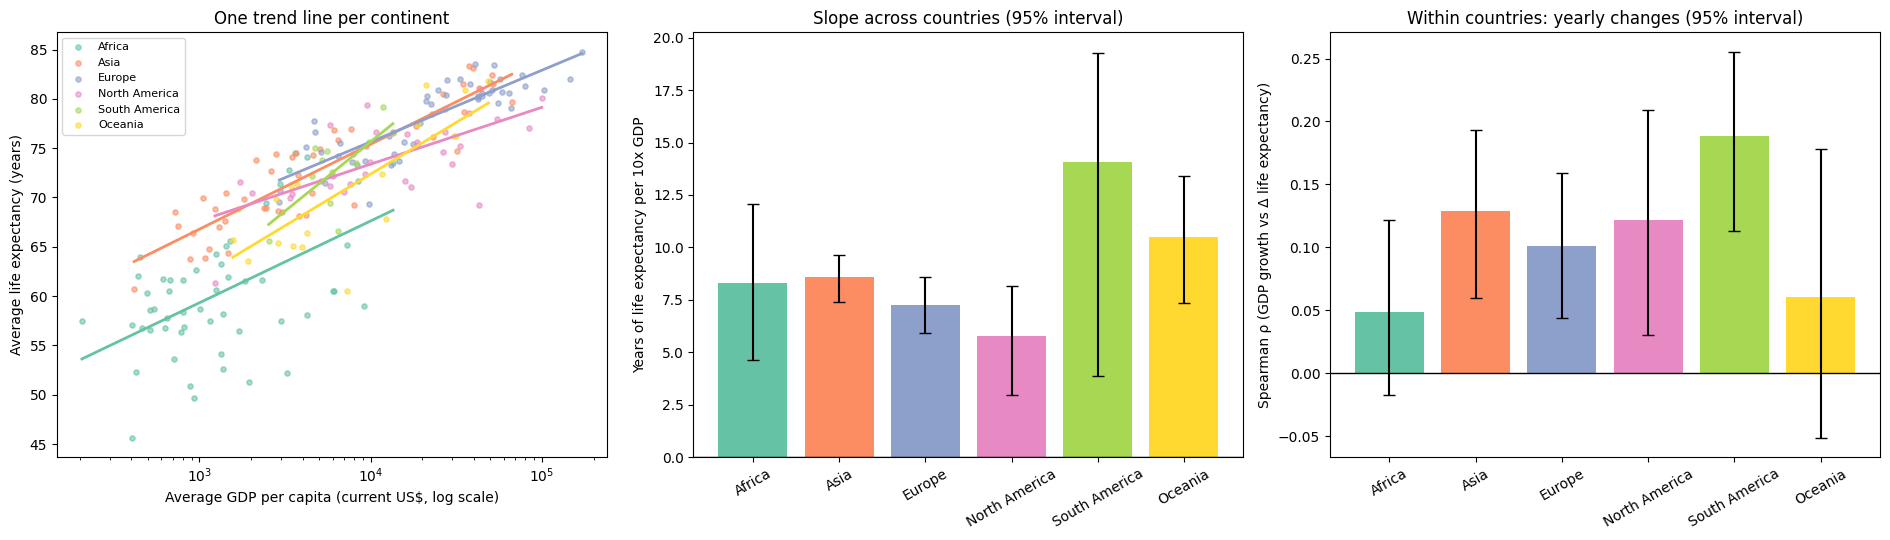

                n   rho  rho_lo  rho_hi  slope  slope_lo  slope_hi  rho_chg  chg_lo  chg_hi
continent                                                                                  
Africa         54  0.45    0.19    0.65   8.30      4.61     12.07     0.05   -0.02    0.12
Asia           48  0.89    0.78    0.94   8.61      7.42      9.65     0.13    0.06    0.19
Europe         48  0.81    0.69    0.88   7.26      5.92      8.59     0.10    0.04    0.16
North America  32  0.65    0.30    0.87   5.76      2.97      8.15     0.12    0.03    0.21
South America  12  0.59   -0.15    0.93  14.07      3.86     19.29     0.19    0.11    0.26
Oceania        19  0.69    0.30    0.88  10.48      7.35     13.42     0.06   -0.05    0.18


In [27]:
# Figure 13: GDP vs life expectancy, continent by continent.
from scipy.stats import spearmanr

rng = np.random.default_rng(42)
n_boot = 1000
panel['continent'] = panel['Country Code'].map(continent_of)

bc = by_country.dropna(subset=['gdp_per_capita', 'life_expectancy']).copy()
bc['log_gdp'] = np.log10(bc['gdp_per_capita'])
chg_c = panel.dropna(subset=['continent', 'gdp_growth_pct', 'd_life_exp'])

def ci(vals):
    return np.nanpercentile(vals, [2.5, 97.5])

rows = []
for cont in cont_order:
    d = bc[bc['continent'] == cont]
    x, y = d['log_gdp'].to_numpy(), d['life_expectancy'].to_numpy()
    rho = spearmanr(x, y)[0]
    slope = np.polyfit(x, y, 1)[0]
    rhos, slopes = [], []
    for _ in range(n_boot):
        i = rng.integers(0, len(d), len(d))
        rhos.append(spearmanr(x[i], y[i])[0])
        slopes.append(np.polyfit(x[i], y[i], 1)[0] if np.ptp(x[i]) > 0 else np.nan)

    g = chg_c[chg_c['continent'] == cont]
    per_country = [(c['gdp_growth_pct'].to_numpy(), c['d_life_exp'].to_numpy()) for _, c in g.groupby('Country Name')]
    rho_chg = spearmanr(g['gdp_growth_pct'], g['d_life_exp'])[0]
    rhos_chg = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(per_country), len(per_country))
        rhos_chg.append(spearmanr(np.concatenate([per_country[k][0] for k in pick]),
                                  np.concatenate([per_country[k][1] for k in pick]))[0])
    rows.append(dict(continent=cont, n=len(d), rho=rho, rho_lo=ci(rhos)[0], rho_hi=ci(rhos)[1],
                     slope=slope, slope_lo=ci(slopes)[0], slope_hi=ci(slopes)[1],
                     rho_chg=rho_chg, chg_lo=ci(rhos_chg)[0], chg_hi=ci(rhos_chg)[1]))
cres = pd.DataFrame(rows).set_index('continent')

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

ax = axes[0]
palette = dict(zip(cont_order, sns.color_palette('Set2', len(cont_order))))
for cont in cont_order:
    d = bc[bc['continent'] == cont]
    ax.scatter(d['gdp_per_capita'], d['life_expectancy'], s=14, alpha=0.6, color=palette[cont], label=cont)
    b = np.polyfit(d['log_gdp'], d['life_expectancy'], 1)
    xs = np.linspace(d['log_gdp'].min(), d['log_gdp'].max(), 50)
    ax.plot(10 ** xs, b[0] * xs + b[1], color=palette[cont], lw=2)
ax.set_xscale('log')
ax.set_xlabel('Average GDP per capita (current US$, log scale)')
ax.set_ylabel('Average life expectancy (years)')
ax.set_title('One trend line per continent')
ax.legend(fontsize=8)

for ax, col, lo, hi, title, ylabel in [
        (axes[1], 'slope', 'slope_lo', 'slope_hi', 'Slope across countries', 'Years of life expectancy per 10x GDP'),
        (axes[2], 'rho_chg', 'chg_lo', 'chg_hi', 'Within countries: yearly changes', 'Spearman ρ (GDP growth vs Δ life expectancy)')]:
    ax.bar(cres.index, cres[col], color=[palette[c] for c in cres.index],
           yerr=[cres[col] - cres[lo], cres[hi] - cres[col]], capsize=4)
    ax.axhline(0, color='black', lw=1)
    ax.set_ylabel(ylabel)
    ax.set_title(f'{title} (95% interval)')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

print(cres.round(2).to_string())

### Answer (Question 11)

- **Yes, in how tightly income predicts life expectancy, but not in how much.** Across countries the correlation is strongest in **Asia (ρ = 0.89)** and **Europe (0.81)**, and weakest in **Africa (0.45, interval 0.19 to 0.65)**. Africa's interval is clearly below both Asia's (0.78 to 0.94) and Europe's (0.69 to 0.88). North America (0.65), Oceania (0.69) and South America (0.59) fall in between, with intervals wide enough to overlap everything, so they cannot be ranked.
- **The size of the link (years per 10x GDP) does not clearly differ by continent.** Point estimates run from 5.8 (North America) to 10.5 (Oceania), with Africa at 8.3, Asia 8.6 and Europe 7.3, but the intervals overlap heavily. South America's 14.1 is the highest, but its interval (3.9 to 19.3) is too wide to say anything with only 12 countries.
- **Every continent's slope except South America's is below the all-country value of 10.9 years per 10x GDP (Question 3).** This suggests part of the worldwide link comes from differences between continents (rich Europe against poorer Africa) and not only from differences within them. This was not tested directly.
- **Within countries, yearly GDP growth barely moves life expectancy anywhere.** Correlations of yearly changes range from 0.05 to 0.19. They are positive and clearly above zero in South America (0.19), Asia (0.13), North America (0.12) and Europe (0.10), but not clearly different from zero in Africa (0.05) and Oceania (0.06). Differences between continents here are small and mostly within the intervals.
- **Decision:** income is a good predictor of life expectancy among Asian and European countries, but a weak one among African countries, where similar-income countries can have very different life expectancy. For Africa, look at non-income factors (health systems, disease burden, conflict) rather than GDP alone. Why the link is weaker there is not tested.
- *Caveats:* small samples (South America 12, Oceania 19 countries); non-overlapping intervals are a rough guide, not a formal test; a narrower income range within a continent can lower its correlation; GDP is in current US$ (not PPP); continents come from a hand-made mapping.

## 13. Question 12: Which continent saw the largest life expectancy gain, and how did GDP per capita change over the same period?

For each country we take life expectancy and GDP per capita in its first and last year with data and compare them, keeping only countries whose data start by 2003 and run to at least 2021 so the periods are comparable. We then take the **median across countries** in each continent (so one large or tiny country does not dominate), with a 95% interval for the median gain from resampling countries 1,000 times. GDP is in current US$, so its change mixes real growth with inflation and exchange-rate moves. Uses `df` and `continent_of` from Questions 1 and 10.

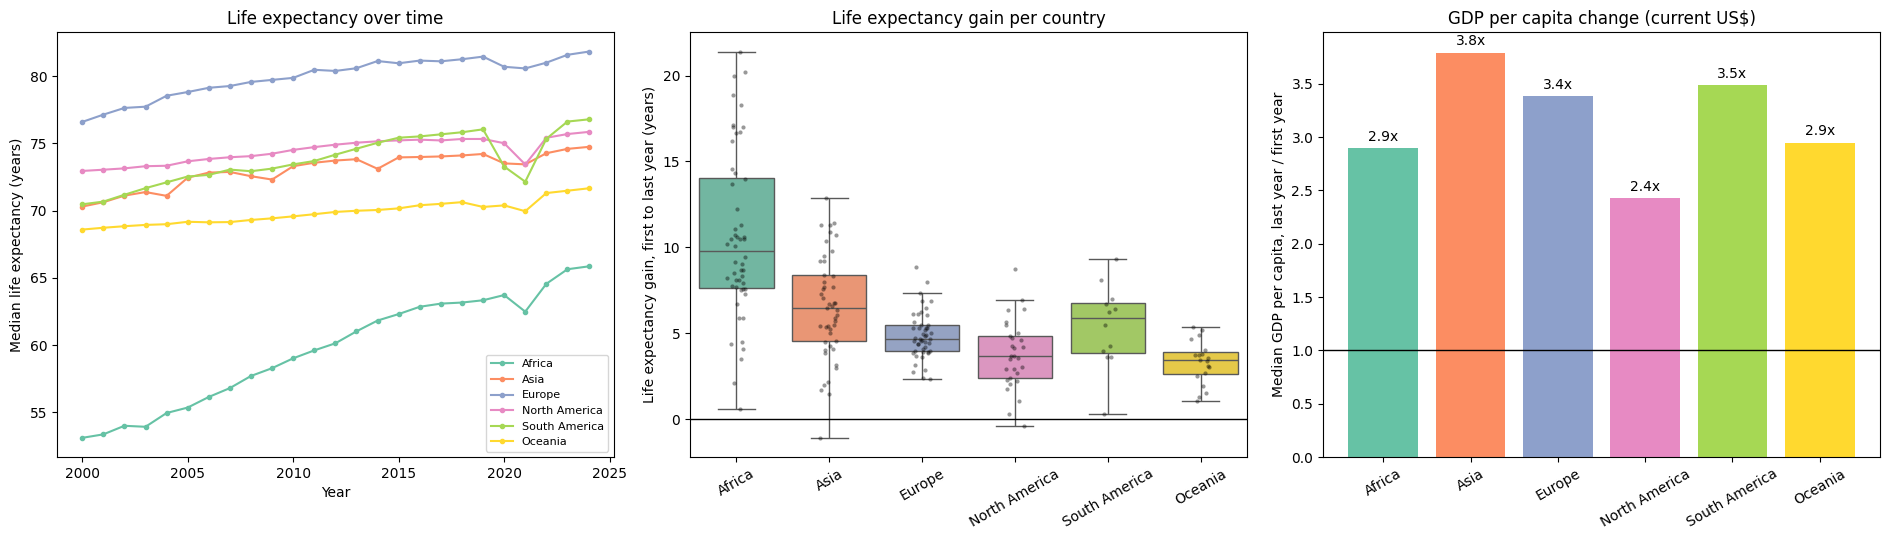

206 countries kept (data from <= 2003 to >= 2021).
                n  le_start  le_end  gain  gain_lo  gain_hi  gain_to_2019  gdp_start  gdp_end  gdp_multiple
continent                                                                                                  
Africa         52      53.1    65.8   9.8      8.3     10.7           7.7      523.6   1716.8           2.9
Asia           47      70.9    74.9   6.5      5.4      7.3           5.8     1138.2   6073.6           3.8
Europe         47      76.6    81.8   4.7      4.4      5.2           4.3    14388.4  38674.3           3.4
North America  29      72.5    75.1   3.7      2.9      4.6           3.0     6178.6  18853.3           2.4
South America  12      70.5    76.8   5.9      3.8      6.8           5.1     2271.6   8238.7           3.5
Oceania        19      68.6    71.7   3.4      2.7      3.8           2.7     2264.8   7590.3           2.9

Largest median gain: Africa (9.8 years)


In [28]:
# Figure 14: change from the first to the last year of data, by continent.
d14 = df.dropna(subset=['continent']).sort_values(['Country Name', 'year'])

def first_last(col):
    """First/last non-missing year and value per country for one indicator."""
    s = d14.dropna(subset=[col])
    g = s.groupby('Country Name')
    return pd.DataFrame({'y0': g['year'].first(), 'y1': g['year'].last(),
                         'v0': g[col].first(), 'v1': g[col].last()})

le_fl, gdp_fl = first_last('life_expectancy'), first_last('gdp_per_capita')
ok = (le_fl['y0'] <= 2003) & (le_fl['y1'] >= 2021) & (gdp_fl['y0'] <= 2003) & (gdp_fl['y1'] >= 2021)
change = pd.DataFrame({
    'continent': d14.groupby('Country Name')['continent'].first(),
    'le_start': le_fl['v0'], 'le_end': le_fl['v1'],
    'gdp_start': gdp_fl['v0'], 'gdp_end': gdp_fl['v1']}).loc[ok[ok].index.intersection(gdp_fl.index)].dropna()
change['le_gain'] = change['le_end'] - change['le_start']
change['gdp_multiple'] = change['gdp_end'] / change['gdp_start']        # 2.0 means GDP per capita doubled

# Life expectancy gain up to 2019 (before COVID-19) for comparison
le19 = df.pivot(index='Country Name', columns='year', values='life_expectancy')
change['le_gain_2019'] = (le19[2019] - le19[2000]).reindex(change.index)

rng = np.random.default_rng(42)
def median_ci(v, reps=1000):
    v = v.to_numpy()
    meds = [np.median(rng.choice(v, len(v))) for _ in range(reps)]
    return np.percentile(meds, [2.5, 97.5])

rows = []
for cont in cont_order:
    c = change[change['continent'] == cont]
    lo, hi = median_ci(c['le_gain'])
    rows.append(dict(continent=cont, n=len(c), le_start=c['le_start'].median(), le_end=c['le_end'].median(),
                     gain=c['le_gain'].median(), gain_lo=lo, gain_hi=hi,
                     gain_to_2019=c['le_gain_2019'].median(),
                     gdp_start=c['gdp_start'].median(), gdp_end=c['gdp_end'].median(),
                     gdp_multiple=c['gdp_multiple'].median()))
cres12 = pd.DataFrame(rows).set_index('continent')

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

ax = axes[0]
med_le = df.dropna(subset=['continent']).groupby(['year', 'continent'])['life_expectancy'].median().unstack()
for cont in cont_order:
    ax.plot(med_le.index, med_le[cont], marker='o', ms=3, color=palette[cont], label=cont)
ax.set_xlabel('Year')
ax.set_ylabel('Median life expectancy (years)')
ax.set_title('Life expectancy over time')
ax.legend(fontsize=8)

ax = axes[1]
sns.boxplot(data=change, x='continent', y='le_gain', order=cont_order, hue='continent', legend=False,
            palette=palette, ax=ax, showfliers=False)
sns.stripplot(data=change, x='continent', y='le_gain', order=cont_order, color='black', alpha=0.4, size=3, ax=ax)
ax.axhline(0, color='black', lw=1)
ax.set_xlabel('')
ax.set_ylabel('Life expectancy gain, first to last year (years)')
ax.set_title('Life expectancy gain per country')
ax.tick_params(axis='x', rotation=30)

ax = axes[2]
bars = ax.bar(cres12.index, cres12['gdp_multiple'], color=[palette[c] for c in cres12.index])
ax.bar_label(bars, fmt='%.1fx', padding=3)
ax.axhline(1, color='black', lw=1)
ax.set_ylabel('Median GDP per capita, last year / first year')
ax.set_title('GDP per capita change (current US$)')
ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

print(f'{len(change)} countries kept (data from <= 2003 to >= 2021).')
print(cres12.round(1).to_string())
print('\nLargest median gain:', cres12['gain'].idxmax(), f"({cres12['gain'].max():.1f} years)")

### Answer (Question 12)

- **Africa saw the largest life expectancy gain: a median of 9.8 years per country** (from 53.1 to 65.8, 52 countries, 95% interval 8.3 to 10.7). It is clearly the largest: the next, Asia (6.5 years, interval 5.4 to 7.3), is entirely below Africa's interval. Then come South America (5.9), Europe (4.7), North America (3.7) and Oceania (3.4).
- **GDP per capita grew in every continent, but Africa's growth was middling.** The median country's GDP per capita rose 2.9x in Africa (from about $520 to $1,720), against 3.8x in Asia (the fastest), 3.5x in South America, 3.4x in Europe, 2.9x in Oceania and 2.4x in North America (the slowest). So the biggest health gain did not come with the fastest GDP growth: Asia grew faster but gained 3.3 fewer years.
- **The gains mostly went to where life expectancy started lowest.** Africa started at 53.1 years and Europe at 76.6; the gain shrinks as the starting point rises, with Oceania the exception (it started at 68.6 and gained the least). This is consistent with Question 5, where yearly GDP growth barely moved life expectancy: gains look driven by catching up on basic health improvements, not by how fast GDP grew. That reading is not tested here.
- **COVID-19 did not erase the gains.** The median gain up to 2019 was already 7.7 years in Africa and 2.7 to 5.8 elsewhere, and each continent's gain to the last year is larger still (differences of medians, so approximate).
- **Decision:** when judging health progress, compare each continent to its own starting point; Africa's improvement is the largest even though it is still the lowest in level (65.8 years against 81.8 in Europe, a gap that narrowed from about 23 to 16 years).
- *Caveats:* medians across countries, with each country counted equally whatever its population; GDP is in current US$, so its change mixes real growth with inflation and exchange rates (the dollar changes are larger for rich continents, about +$24,000 in Europe against about +$1,200 in Africa); "last year" is the final year with data (2021 or later), which differs slightly between countries; South America (12 countries) and Oceania (19) have wide uncertainty.